# Inverse FX Chain Predictor — Phase 1: **Log-Mel + Transformer** → Effect-Type Prediction

Predict which effects — **EQ, Compressor, Reverb** — were applied, from **dry audio + wet audio only**.
Multi-label classification: 3 logits `[EQ, Compressor, Reverb]`, `BCEWithLogitsLoss`, sigmoid at inference.

```
Dry Audio ──> Log-Mel ──┐
                        ├──> Feature Fusion (concat) ──> Transformer Encoder ──> [CLS] ──> Classification Head ──> [EQ, Compressor, Reverb]
Wet Audio ──> Log-Mel ──┘
```

**Dataset:** [`APINAJA/inverse-fx-phase1-effect-type`](https://huggingface.co/datasets/APINAJA/inverse-fx-phase1-effect-type) (existing `train`/`validation`/`test` splits, not regenerated)
**Model repo:** `APINAJA/inverse-fx-phase1-logmel-transformer` (checkpoints, best model, results, TensorBoard)

### Before you run (Kaggle settings panel)
1. **Accelerator:** `GPU T4 x2` &nbsp; 2. **Internet:** ON &nbsp; 3. **Add-ons → Secrets:** add `HF_TOKEN` (a *write* token) and tick it for this notebook.

### How to run
* **First run / every run:** *Run All* (or **Save Version → Save & Run All** to train in the background for up to 12 h).
* **After a Kaggle interruption:** start a new session and *Run All* again — nothing to edit. With
  `RESUME_FROM_CHECKPOINT = "auto"` the notebook finds the newest checkpoint (local or on the Hub), downloads it,
  restores model/optimizer/scheduler/AMP-scaler/history and continues at the next epoch.

### How the code is organised
DDP inside a Jupyter kernel is fragile, so each section writes its part of a small package (`fxp1/`) with
`%%writefile`, the notebook imports it for inspection / smoke tests / final evaluation, and training runs as
`torchrun --nproc_per_node=<#GPUs> train.py` (one process per T4). All settings live in **Section 4**.

## 1. Environment Setup

In [7]:
import os, sys, json, time, shutil, platform, subprocess, importlib

IS_KAGGLE = os.path.exists("/kaggle/working")
WORK_DIR = "/kaggle/working" if IS_KAGGLE else os.path.abspath("./phase1_work")
PKG_DIR = os.path.join(WORK_DIR, "fxp1")           # package written by the %%writefile cells
os.makedirs(PKG_DIR, exist_ok=True)
os.chdir(WORK_DIR)
if WORK_DIR not in sys.path:
    sys.path.insert(0, WORK_DIR)

os.environ.setdefault("OMP_NUM_THREADS", "2")       # Kaggle has 4 vCPUs shared by 2 DDP ranks + workers
os.environ.setdefault("TOKENIZERS_PARALLELISM", "false")
os.environ["HF_HUB_DISABLE_TELEMETRY"] = "1"
os.environ["PYTHONUNBUFFERED"] = "1"
# Silence all progress bars (HF upload/download, datasets, tqdm) in the notebook AND in the torchrun workers
os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"
os.environ["HF_DATASETS_DISABLE_PROGRESS_BARS"] = "1"
os.environ["TQDM_DISABLE"] = "1"

print(f"Kaggle: {IS_KAGGLE} | Python {platform.python_version()} | WORK_DIR={WORK_DIR}")
print(f"CPUs: {os.cpu_count()} | disk free in {WORK_DIR}: {shutil.disk_usage(WORK_DIR).free / 1e9:.1f} GB")
_hf_home = os.environ.get("HF_HOME", os.path.expanduser("~/.cache/huggingface"))
os.makedirs(_hf_home, exist_ok=True)
_free = shutil.disk_usage(_hf_home).free / 1e9
print(f"HF cache {_hf_home}: {_free:.1f} GB free (dataset needs ~15 GB: 6.7 GB download + Arrow cache)")
if _free < 16:
    print("WARNING: possibly not enough disk for the dataset cache.")

Kaggle: True | Python 3.13.15 | WORK_DIR=/kaggle/working
CPUs: 4 | disk free in /kaggle/working: 20.9 GB
HF cache /root/.cache/huggingface: 1148.8 GB free (dataset needs ~15 GB: 6.7 GB download + Arrow cache)


## 2. Install Dependencies
Only missing packages are installed; Kaggle's preinstalled PyTorch/CUDA build is never touched.

In [8]:
REQUIRED = {  # import name -> pip spec
    "datasets": "datasets>=2.19", "huggingface_hub": "huggingface_hub>=0.23", "soundfile": "soundfile>=0.12",
    "librosa": "librosa>=0.10", "tensorboard": "tensorboard", "pandas": "pandas", "matplotlib": "matplotlib",
}
missing = [spec for mod, spec in REQUIRED.items() if importlib.util.find_spec(mod) is None]
if missing:
    print("Installing:", missing)
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])
else:
    print("All dependencies already installed.")

All dependencies already installed.


## 3. Imports

In [9]:
%matplotlib inline
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import datasets, huggingface_hub, librosa, soundfile
datasets.disable_progress_bars()
huggingface_hub.utils.disable_progress_bars()
import matplotlib.pyplot as plt
from IPython.display import Image, display, Markdown

print(f"torch {torch.__version__} | datasets {datasets.__version__} | huggingface_hub {huggingface_hub.__version__} | "
      f"librosa {librosa.__version__} | soundfile {soundfile.__version__}")

torch 2.11.0+cu128 | datasets 4.8.5 | huggingface_hub 1.29.0 | librosa 0.11.0 | soundfile 0.14.0


## 4. Configuration
**Every experiment parameter lives here.** The dict is written to `experiment_config.json`, which the `torchrun`
training processes read, and is stored inside every checkpoint.

Notes
* `BATCH_SIZE` is **per GPU** — effective batch = `BATCH_SIZE × #GPUs` (16 × 2 = 32 on 2×T4).

**Settings chosen for the current dataset** (2,191 train / 483 validation / 462 test pairs; 313 / 69 / 66 dry clips × 7
combinations; song-level split):

| setting | value | why |
|---|---|---|
| batch | 16 per GPU → 32 | 69 steps/epoch; T4 memory is far from full at 863 tokens × d_model 256 |
| epochs | 40 (+ early stopping, patience 10) | ≈ 2,760 steps; with ~2.2 k pairs a 2.2 M-parameter model usually peaks well before that |
| LR / warm-up | 3e-4 AdamW, 2 warm-up epochs, cosine to 2 % | standard for a small Transformer at batch 32 |
| regularisation | weight decay 0.05, dropout 0.1, grad-clip 1.0 | no augmentation: level/dynamics are the evidence |
| class balance | none needed | every dry clip appears in all 7 combinations → each effect is positive in 4/7 of the pairs |
| checkpoints | every 5 epochs + last epoch, `best/` kept locally and pushed with them | ≈ 9 pushes of ~27 MB |
| printing | 1 progress line / 50 steps + 1 summary line / epoch | ≈ 100 lines for the whole run |

Expected time on 2×T4: roughly 30–60 s per epoch (mostly audio decoding), i.e. ~20–40 min for 40 epochs, plus a one-off
5–10 min to download and prepare the 6.7 GB dataset.
* `NORM_MEAN/NORM_STD = None` → estimated from training audio in Section 12 (stored in config + checkpoints).
* `RESUME_FROM_CHECKPOINT`: `"auto"` (local → Hub → fresh), `None` (fresh), a local path, or a checkpoint name like `"checkpoint_epoch_005"`.
* To train longer after a finished run, raise `NUM_EPOCHS` and re-run: training continues from the latest checkpoint
  (the cosine schedule is re-stretched to the new length).

In [10]:
CFG = dict(
    # --- reproducibility --------------------------------------------------------------
    SEED=42,
    DETERMINISTIC=False,               # True = deterministic kernels where available (slower, warn-only)

    # --- data (existing HF dataset; inputs = dry + wet audio ONLY) --------------------
    HF_DATASET_ID="APINAJA/inverse-fx-phase1-effect-type",
    HF_DATASET_REVISION="b95597add82924cbe82b2e7015c057ffa2a51fba",   # dataset commit of 2026-10-13
                                       # (2,191 / 483 / 462 pairs). Pinned so every session trains on the
                                       # same data; change it only if you update the dataset again.
    HF_DATASET_LOCAL_PATH=None,
    HF_DATASETS_CACHE=None,            # None = default HF cache
    DRY_AUDIO_COLUMN="dry_audio",
    WET_AUDIO_COLUMN="wet_audio",
    LABEL_COLUMNS=["eq_label", "compressor_label", "reverb_label"],   # -> outputs [EQ, Compressor, Reverb]
    ID_COLUMN="sample_id",

    # --- audio preprocessing (Phase 1 spec) -------------------------------------------
    SAMPLE_RATE=44100,                 # Hz
    AUDIO_LENGTH_SECONDS=10.0,         # fixed length: crop from start / zero-pad at end
    RESAMPLE_TYPE="soxr_hq",           # only used if a file is not already 44.1 kHz

    # --- Log-Mel (identical for dry and wet) ------------------------------------------
    N_FFT=2048,
    HOP_LENGTH=512,                    # 441000 samples -> 1 + 441000 // 512 = 862 frames
    WIN_LENGTH=None,                   # None = N_FFT (Hann window)
    N_MELS=128,
    F_MIN=20.0,
    F_MAX=20000.0,
    LOG_EPS=1e-6,
    NORM_MEAN=None,                    # filled in Section 12 from training audio
    NORM_STD=None,
    NORM_STATS_NUM_EXAMPLES=128,       # train clips used for the global log-mel mean/std

    # --- feature fusion ----------------------------------------------------------------
    FUSION="concat",                   # [B,T,M] ++ [B,T,M] -> [B,T,2M]  ("concat_diff" adds wet-dry -> 3M)

    # --- Transformer ---------------------------------------------------------------------
    D_MODEL=256,
    N_HEAD=4,
    NUM_LAYERS=4,
    DIM_FEEDFORWARD=512,
    DROPOUT=0.1,
    HEAD_HIDDEN_DIM=128,
    HEAD_DROPOUT=0.1,

    # --- optimisation -------------------------------------------------------------------
    BATCH_SIZE=16,                     # per GPU -> effective 32 on 2xT4 -> 69 optimizer steps / epoch
    EVAL_BATCH_SIZE=16,                # per GPU
    LEARNING_RATE=3e-4,
    NUM_EPOCHS=40,                     # 40 x 69 = 2,760 optimizer steps (early stopping may end it sooner)
    WEIGHT_DECAY=0.05,
    ADAM_BETAS=[0.9, 0.98],
    ADAM_EPS=1e-8,
    WARMUP_EPOCHS=2,                   # ~140 warm-up steps
    MIN_LR_RATIO=0.02,
    USE_AMP=True,                      # torch.amp autocast float16 + GradScaler (CUDA only)
    GRADIENT_CLIPPING=1.0,             # max grad-norm; None disables
    THRESHOLD=0.5,                     # sigmoid probability threshold
    BEST_METRIC="macro_f1",            # validation metric used to select best/ (never test)
    BEST_METRIC_MODE="max",
    MIN_DELTA=0.0,
    EARLY_STOPPING_PATIENCE=10,        # stop if validation macro-F1 has not improved for 10 epochs; None = off
    LOG_EVERY_N_STEPS=10,              # TensorBoard step-level scalars (no printing)
    PRINT_EVERY_N_STEPS=50,            # one "step X/total" progress line every 50 optimizer steps

    # --- data loading -------------------------------------------------------------------
    NUM_WORKERS=2,                     # per GPU process (Kaggle: 4 vCPUs)
    PIN_MEMORY=True,
    PERSISTENT_WORKERS=True,
    PREFETCH_FACTOR=2,

    # --- multi-GPU -----------------------------------------------------------------------
    USE_DDP=True,                      # torchrun + DistributedDataParallel across all visible GPUs
    DDP_TIMEOUT_MINUTES=60,
    FORCE_CPU=False,

    # --- checkpointing / resume ----------------------------------------------------------
    CHECKPOINT_EVERY_N_EPOCHS=5,       # save checkpoint_epoch_XXX + push to the Hub every N epochs (and at the last epoch).
                                       # best/ is updated locally whenever validation improves and is pushed with the next one.
                                       # After an interruption, at most N-1 epochs are redone.
    RESUME_FROM_CHECKPOINT="auto",     # "auto" | None | "/path/to/checkpoint_epoch_XXX" | "checkpoint_epoch_XXX"
    WORK_DIR=WORK_DIR,
    CHECKPOINT_DIR=os.path.join(WORK_DIR, "checkpoints"),
    TENSORBOARD_DIR=os.path.join(WORK_DIR, "runs", "phase1_logmel_transformer"),
    RESULTS_DIR=os.path.join(WORK_DIR, "results"),

    # --- Hugging Face model repo ------------------------------------------------------------
    HF_MODEL_ID="APINAJA/inverse-fx-phase1-logmel-transformer-v2",   # NEW repo for the new dataset;
                                       # the old repo holds checkpoints trained on the 294-clip version
    PUSH_TO_HUB=True,
    HF_PRIVATE_REPO=True,              # created private if it does not exist
    HF_UPLOAD_RETRIES=3,

    # --- smoke test -------------------------------------------------------------------------
    RUN_SMOKE_TEST=True,
    SMOKE_TEST_DDP=True,               # also run a 2-step DDP train + resume through torchrun
    SMOKE_TEST_HF_UPLOAD=True,         # uploads a tiny checkpoint to <model repo>/smoke_test/
)

assert CFG["HF_MODEL_ID"] != CFG["HF_DATASET_ID"], "Model repo must differ from the dataset repo"
CONFIG_PATH = os.path.join(WORK_DIR, "experiment_config.json")

def save_config():
    with open(CONFIG_PATH, "w") as f:
        json.dump(CFG, f, indent=2)

for d in (CFG["CHECKPOINT_DIR"], CFG["TENSORBOARD_DIR"], CFG["RESULTS_DIR"], os.path.join(CFG["RESULTS_DIR"], "plots")):
    os.makedirs(d, exist_ok=True)
save_config()
print(f"Config written to {CONFIG_PATH} ({len(CFG)} keys)")

Config written to /kaggle/working/experiment_config.json (69 keys)


## 5. Hugging Face Authentication
The token comes from the Kaggle Secret `HF_TOKEN` (or an existing `HF_TOKEN` env var). It is placed in the
process environment so the `torchrun` workers inherit it — it is **never printed or written to disk**.

In [11]:
_tok = None
try:
    from kaggle_secrets import UserSecretsClient
    _tok = UserSecretsClient().get_secret("HF_TOKEN")
except Exception:
    pass
_tok = _tok or os.environ.get("HF_TOKEN")

HF_AUTH_OK = False
if _tok:
    os.environ["HF_TOKEN"] = _tok
    from huggingface_hub import HfApi
    try:
        _who = HfApi(token=_tok).whoami()
        _role = (_who.get("auth", {}).get("accessToken", {}) or {}).get("role", "unknown")
        print(f"Authenticated to Hugging Face as '{_who.get('name')}' (token role: {_role}).")
        HF_AUTH_OK = True
    except Exception as e:
        print(f"WARNING: HF authentication failed ({type(e).__name__}). Checkpoints will stay local only.")
else:
    print("WARNING: no HF_TOKEN found (Kaggle: Add-ons -> Secrets). Training works, but checkpoints stay "
          "local and cannot survive a Kaggle session reset.")
del _tok

Authenticated to Hugging Face as 'APINAJA' (token role: fineGrained).


## 6. GPU Detection
`NPROC` = number of training processes for `torchrun` (one per GPU). The notebook kernel itself only uses a GPU for inspection, smoke tests and the final test evaluation.

In [12]:
print("CUDA available:", torch.cuda.is_available())
NUM_GPUS = torch.cuda.device_count() if (torch.cuda.is_available() and not CFG["FORCE_CPU"]) else 0
print("GPU count:", NUM_GPUS)
if NUM_GPUS:
    print(f"CUDA runtime {torch.version.cuda} | cuDNN {torch.backends.cudnn.version()} | NCCL {torch.cuda.nccl.version() if hasattr(torch.cuda, 'nccl') else 'n/a'}")
    for i in range(NUM_GPUS):
        p = torch.cuda.get_device_properties(i)
        print(f"  cuda:{i}  {p.name} | compute capability {p.major}.{p.minor} | {p.total_memory / 1e9:.1f} GB | {p.multi_processor_count} SMs")
    try:
        print(subprocess.run(["nvidia-smi", "--query-gpu=index,name,driver_version,memory.used,memory.total",
                              "--format=csv"], capture_output=True, text=True).stdout)
    except FileNotFoundError:
        pass
else:
    print("WARNING: No GPU detected -> CPU fallback (very slow; AMP disabled automatically). "
          "On Kaggle select Accelerator = 'GPU T4 x2'.")

NPROC = NUM_GPUS if (CFG["USE_DDP"] and NUM_GPUS > 1) else 1
DEVICE = torch.device("cuda", 0) if NUM_GPUS else torch.device("cpu")   # notebook-side work only
MODE = f"DDP on {NPROC} GPUs" if NPROC > 1 else ("single GPU" if NUM_GPUS else "CPU")
print(f"Training mode: {MODE} (torchrun --nproc_per_node={NPROC}) | effective batch = {CFG['BATCH_SIZE'] * NPROC}")


import re
_PROGRESS_RE = re.compile(r"\d+%\||\|\s*[\d.]+\s*[kMG]?B\s*/|^(Processing Files|New Data Upload|Fetching|Downloading|Generating|Map|Filter)\b")

def run_torchrun(extra_args=(), nproc=None):
    """Launch train.py with torchrun. Shows only real log lines; the full raw output goes to logs/torchrun.log."""
    nproc = nproc or NPROC
    cmd = [sys.executable, "-m", "torch.distributed.run", "--standalone", f"--nproc_per_node={nproc}",
           os.path.join(WORK_DIR, "train.py"), "--config", CONFIG_PATH, *map(str, extra_args)]
    print("$", " ".join(cmd), flush=True)
    log_path = os.path.join(WORK_DIR, "logs", "torchrun.log")
    os.makedirs(os.path.dirname(log_path), exist_ok=True)
    proc = subprocess.Popen(cmd, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True, bufsize=1,
                            env=os.environ.copy())
    lines = []
    try:
        with open(log_path, "a") as logf:
            for line in proc.stdout:
                logf.write(line)
                s = line.strip()
                if not s or _PROGRESS_RE.search(s):      # drop progress-bar refreshes
                    continue
                print(line, end="", flush=True)
                lines.append(line)
        rc = proc.wait()
    except KeyboardInterrupt:                             # stopping the cell also stops training
        proc.terminate()
        proc.wait()
        raise
    if rc != 0:
        raise RuntimeError(f"torchrun exited with code {rc} (full log: {log_path})")
    return lines

CUDA available: True
GPU count: 2
CUDA runtime 12.8 | cuDNN 91900 | NCCL (2, 28, 9)
  cuda:0  Tesla T4 | compute capability 7.5 | 15.6 GB | 40 SMs
  cuda:1  Tesla T4 | compute capability 7.5 | 15.6 GB | 40 SMs
index, name, driver_version, memory.used [MiB], memory.total [MiB]
0, Tesla T4, 580.178.04, 3 MiB, 15360 MiB
1, Tesla T4, 580.178.04, 3 MiB, 15360 MiB

Training mode: DDP on 2 GPUs (torchrun --nproc_per_node=2) | effective batch = 32


## 7. Reproducibility
Seeds Python `random`, NumPy and PyTorch (CPU + every CUDA device). Each DDP rank uses `SEED + rank`, and every epoch
re-seeds with `SEED + 1000·epoch + rank`, so a resumed run replays the same dropout / shuffle streams from the resume
point. Shuffling comes from `DistributedSampler(seed=SEED).set_epoch(epoch)`.

> **Caveat:** exact bit-for-bit reproducibility is still not guaranteed on GPU — cuBLAS/cuDNN algorithm selection,
> atomic-add reductions, FP16 loss-scaling dynamics and NCCL all-reduce ordering are non-deterministic, and results
> can differ across PyTorch/CUDA versions or GPU counts. `DETERMINISTIC=True` narrows (not eliminates) the gap.

In [13]:
%%writefile {PKG_DIR}/__init__.py
"""Phase 1 Inverse FX Chain Predictor: Log-Mel + Transformer."""

Overwriting /kaggle/working/fxp1/__init__.py


In [14]:
%%writefile {PKG_DIR}/common.py
"""Shared constants and utilities for the Phase 1 Inverse FX Chain Predictor.

Label mapping (multi-label, 3 sigmoid outputs):
    index 0 -> EQ          (dataset column: eq_label)
    index 1 -> Compressor  (dataset column: compressor_label)
    index 2 -> Reverb      (dataset column: reverb_label)

The 7 valid non-empty combinations are the 7 non-zero binary vectors over
those 3 outputs. They are used ONLY for reporting (7-combination accuracy and
the 7x7 confusion matrix); the model is never trained with a 7-way softmax.
"""
from __future__ import annotations

import json
import os
import random
import sys
import tempfile
import time
from typing import Any, Dict, List, Tuple

import numpy as np
import torch

EFFECTS: List[str] = ["EQ", "Compressor", "Reverb"]

# (display name, binary vector) in the order fixed by the Phase 1 plan.
COMBINATIONS: List[Tuple[str, Tuple[int, int, int]]] = [
    ("EQ", (1, 0, 0)),
    ("Compressor", (0, 1, 0)),
    ("Reverb", (0, 0, 1)),
    ("EQ + Compressor", (1, 1, 0)),
    ("EQ + Reverb", (1, 0, 1)),
    ("Compressor + Reverb", (0, 1, 1)),
    ("EQ + Compressor + Reverb", (1, 1, 1)),
]
COMBINATION_NAMES: List[str] = [name for name, _ in COMBINATIONS]
VECTOR_TO_COMBINATION: Dict[Tuple[int, int, int], int] = {
    vec: i for i, (_, vec) in enumerate(COMBINATIONS)
}

# Columns the model is never allowed to see (research-integrity guard).
FORBIDDEN_INPUT_COLUMNS = (
    "effect_chain", "combination", "label", "eq_params", "compressor_params",
    "reverb_params", "parameters", "parameters_normalized", "effect_change_db",
    "low_effect_change", "dry_peak_dbfs", "wet_peak_dbfs",
)


def log(msg: str, rank: int = 0, all_ranks: bool = False) -> None:
    """Rank-aware, timestamped print (flushes so torchrun output streams)."""
    if all_ranks or rank == 0:
        stamp = time.strftime("%H:%M:%S")
        prefix = f"[{stamp}]" + (f"[rank{rank}]" if all_ranks else "")
        print(f"{prefix} {msg}", flush=True)
        sys.stdout.flush()


def set_seed(seed: int, deterministic: bool = False) -> None:
    """Seed Python, NumPy and PyTorch (CPU + all CUDA devices).

    Exact bit-for-bit reproducibility is still NOT guaranteed on GPU: some
    CUDA kernels (atomics in reductions, cuBLAS/cuDNN algorithm choice, AMP
    loss-scaling dynamics, NCCL all-reduce ordering) are non-deterministic.
    `deterministic=True` asks PyTorch for deterministic kernels where they
    exist (warn-only), at some speed cost.
    """
    random.seed(seed)
    np.random.seed(seed % (2**32))
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark = False
    if deterministic:
        os.environ.setdefault("CUBLAS_WORKSPACE_CONFIG", ":4096:8")
        torch.backends.cudnn.deterministic = True
        torch.use_deterministic_algorithms(True, warn_only=True)


def get_rng_state() -> Dict[str, Any]:
    state = {
        "python": random.getstate(),
        "numpy": np.random.get_state(),
        "torch_cpu": torch.get_rng_state(),
    }
    if torch.cuda.is_available():
        state["torch_cuda_all"] = torch.cuda.get_rng_state_all()
    return state


def set_rng_state(state: Dict[str, Any]) -> None:
    try:
        random.setstate(state["python"])
        np.random.set_state(state["numpy"])
        torch.set_rng_state(state["torch_cpu"])
        if torch.cuda.is_available() and "torch_cuda_all" in state:
            cuda_states = state["torch_cuda_all"]
            if len(cuda_states) == torch.cuda.device_count():
                torch.cuda.set_rng_state_all(cuda_states)
    except Exception as exc:  # RNG restore is best-effort
        log(f"WARNING: could not fully restore RNG state ({exc}); continuing.")


def atomic_write_text(path: str, text: str) -> None:
    """Write text to `path` atomically (temp file + fsync + os.replace)."""
    directory = os.path.dirname(os.path.abspath(path))
    os.makedirs(directory, exist_ok=True)
    fd, tmp = tempfile.mkstemp(dir=directory, prefix=".tmp_", suffix=".part")
    try:
        with os.fdopen(fd, "w", encoding="utf-8") as fh:
            fh.write(text)
            fh.flush()
            os.fsync(fh.fileno())
        os.replace(tmp, path)
    finally:
        if os.path.exists(tmp):
            os.remove(tmp)


def atomic_write_json(path: str, obj: Any) -> None:
    atomic_write_text(path, json.dumps(obj, indent=2, sort_keys=False, default=_json_default))


def _json_default(o: Any) -> Any:
    if isinstance(o, (np.integer,)):
        return int(o)
    if isinstance(o, (np.floating,)):
        return float(o)
    if isinstance(o, np.ndarray):
        return o.tolist()
    if isinstance(o, torch.Tensor):
        return o.detach().cpu().tolist()
    return str(o)


def read_json(path: str) -> Any:
    with open(path, "r", encoding="utf-8") as fh:
        return json.load(fh)


def load_config(path: str) -> Dict[str, Any]:
    cfg = read_json(path)
    cfg["_config_path"] = path
    return cfg


def expected_num_frames(cfg: Dict[str, Any]) -> int:
    """STFT frames for a fixed-length clip with center=True padding."""
    num_samples = int(round(cfg["SAMPLE_RATE"] * cfg["AUDIO_LENGTH_SECONDS"]))
    return 1 + num_samples // int(cfg["HOP_LENGTH"])


def fused_feature_dim(cfg: Dict[str, Any]) -> int:
    n_mels = int(cfg["N_MELS"])
    return {"concat": 2 * n_mels, "concat_diff": 3 * n_mels}[cfg["FUSION"]]


# Settings that define WHICH experiment a checkpoint belongs to. A checkpoint is only
# resumed if these match the current config (NUM_EPOCHS, LR, batch size, etc. may change).
FINGERPRINT_KEYS = (
    "HF_DATASET_ID", "HF_DATASET_REVISION", "DRY_AUDIO_COLUMN", "WET_AUDIO_COLUMN", "LABEL_COLUMNS",
    "SAMPLE_RATE", "AUDIO_LENGTH_SECONDS", "N_FFT", "HOP_LENGTH", "WIN_LENGTH", "N_MELS", "F_MIN", "F_MAX",
    "FUSION", "D_MODEL", "N_HEAD", "NUM_LAYERS", "DIM_FEEDFORWARD", "HEAD_HIDDEN_DIM",
)


def run_fingerprint(cfg: Dict[str, Any]) -> Dict[str, Any]:
    return {k: cfg.get(k) for k in FINGERPRINT_KEYS}


def fingerprint_mismatch(saved_cfg: Dict[str, Any], cfg: Dict[str, Any]) -> Dict[str, Any]:
    """{key: (in checkpoint, now)} for every differing fingerprint key (empty = compatible)."""
    a, b = run_fingerprint(saved_cfg), run_fingerprint(cfg)
    return {k: (a[k], b[k]) for k in FINGERPRINT_KEYS if a[k] != b[k]}

Overwriting /kaggle/working/fxp1/common.py


In [15]:
from fxp1.common import set_seed, EFFECTS, COMBINATIONS, COMBINATION_NAMES
set_seed(CFG["SEED"], CFG["DETERMINISTIC"])
print("Seed set:", CFG["SEED"], "| deterministic kernels:", CFG["DETERMINISTIC"])

Seed set: 42 | deterministic kernels: False


## 8. Load Dataset
The parquet shards (~0.9 GB) are downloaded once into the HF cache and memory-mapped — audio is **not** loaded into RAM. The dataset is used as-is (never regenerated or modified).

In [16]:
from datasets import load_dataset
_kw = {k: v for k, v in (("revision", CFG["HF_DATASET_REVISION"]), ("cache_dir", CFG["HF_DATASETS_CACHE"])) if v}
raw = load_dataset(CFG["HF_DATASET_LOCAL_PATH"] or CFG["HF_DATASET_ID"], **_kw)
print(raw)
assert {"train", "validation", "test"} <= set(raw.keys()), f"Expected train/validation/test, got {list(raw.keys())}"

DatasetDict({
    train: Dataset({
        features: ['sample_id', 'source_sample_id', 'source_id', 'source_category', 'source_song', 'split', 'dry_audio', 'wet_audio', 'effect_chain', 'combination', 'label', 'eq_label', 'compressor_label', 'reverb_label', 'eq_params', 'compressor_params', 'reverb_params', 'parameters', 'parameters_normalized', 'effect_change_db', 'low_effect_change', 'sample_rate', 'num_channels', 'duration_s', 'dry_peak_dbfs', 'wet_peak_dbfs', 'dsp_backend', 'parameter_mode', 'random_seed', 'sample_seed'],
        num_rows: 2191
    })
    validation: Dataset({
        features: ['sample_id', 'source_sample_id', 'source_id', 'source_category', 'source_song', 'split', 'dry_audio', 'wet_audio', 'effect_chain', 'combination', 'label', 'eq_label', 'compressor_label', 'reverb_label', 'eq_params', 'compressor_params', 'reverb_params', 'parameters', 'parameters_normalized', 'effect_change_db', 'low_effect_change', 'sample_rate', 'num_channels', 'duration_s', 'dry_peak_dbfs'

## 9. Inspect Dataset
Label sanity checks, the 7-combination distribution per split, and source overlap between splits (useful context for interpreting results — the split itself is not changed).

In [17]:
meta_cols = ["sample_id", "source_song", "source_category", "combination", "eq_label", "compressor_label",
             "reverb_label", "sample_rate", "num_channels", "duration_s"]
frames = {s: raw[s].select_columns([c for c in meta_cols if c in raw[s].column_names]).to_pandas() for s in raw}

for s, df in frames.items():
    vec = df[CFG["LABEL_COLUMNS"]].to_numpy()
    assert set(np.unique(vec)) <= {0, 1}, "labels must be binary"
    assert (vec.sum(1) > 0).all(), "every example must have at least one effect"
    if "combination" in df:   # label columns must agree with the combination string (metadata check only)
        rebuilt = ["+".join(e for e, b in zip(EFFECTS, row) if b) for row in vec]
        mism = (np.array(rebuilt) != df["combination"].to_numpy()).sum()
        print(f"{s:<10} n={len(df):>4} | label/combination mismatches: {mism} | sample_rate {sorted(df.sample_rate.unique())} "
              f"| channels {sorted(df.num_channels.unique())} | duration_s {sorted(df.duration_s.unique())}")

dist_tbl = pd.DataFrame({s: pd.Series(["+".join(e for e, b in zip(EFFECTS, r) if b) for r in df[CFG["LABEL_COLUMNS"]].to_numpy()]).value_counts()
                         for s, df in frames.items()}).reindex([n.replace(" + ", "+") for n in COMBINATION_NAMES]).fillna(0).astype(int)
dist_tbl.index = COMBINATION_NAMES
display(Markdown("**Examples per combination**")); display(dist_tbl)
if "source_category" in frames["train"]:
    display(Markdown("**Examples per source category**"))
    display(pd.DataFrame({s: df["source_category"].value_counts() for s, df in frames.items()}).fillna(0).astype(int))
if "source_song" in frames["train"]:
    songs = {s: set(df["source_song"]) for s, df in frames.items()}
    print("Source songs per split:", {s: len(v) for s, v in songs.items()})
    print("Song overlap train∩validation:", len(songs["train"] & songs["validation"]),
          "| train∩test:", len(songs["train"] & songs["test"]), "| validation∩test:", len(songs["validation"] & songs["test"]))
print("\nModel inputs are ONLY", CFG["DRY_AUDIO_COLUMN"], "+", CFG["WET_AUDIO_COLUMN"], "| targets:", CFG["LABEL_COLUMNS"])

train      n=2191 | label/combination mismatches: 0 | sample_rate [np.int64(44100)] | channels [np.int64(1)] | duration_s [np.float64(10.0)]
validation n= 483 | label/combination mismatches: 0 | sample_rate [np.int64(44100)] | channels [np.int64(1)] | duration_s [np.float64(10.0)]
test       n= 462 | label/combination mismatches: 0 | sample_rate [np.int64(44100)] | channels [np.int64(1)] | duration_s [np.float64(10.0)]


**Examples per combination**

,train,validation,test
EQ,313,69,66
Compressor,313,69,66
Reverb,313,69,66
EQ + Compressor,313,69,66
EQ + Reverb,313,69,66
Compressor + Reverb,313,69,66
EQ + Compressor + Reverb,313,69,66


**Examples per source category**

,train,validation,test
source_category,,,
Bass,721,161,154
Drums,735,161,154
Mixture,735,161,154


Source songs per split: {'train': 105, 'validation': 23, 'test': 22}
Song overlap train∩validation: 0 | train∩test: 0 | validation∩test: 0

Model inputs are ONLY dry_audio + wet_audio | targets: ['eq_label', 'compressor_label', 'reverb_label']


## 10. Audio Preprocessing
`decode WAV bytes (soundfile) → float32 → mono → resample to 44.1 kHz if needed → crop/zero-pad to exactly 10 s`.
No loudness/peak normalisation: the level and dynamics difference between dry and wet is evidence (especially for the
compressor). Deterministic — no random crops or augmentation.

In [18]:
%%writefile {PKG_DIR}/audio.py
"""Deterministic audio preprocessing (Phase 1 spec).

    decode (soundfile, from the raw bytes stored in the HF parquet)
      -> float32
      -> mono (mean over channels)
      -> resample to SAMPLE_RATE if needed (soxr_hq, deterministic)
      -> fixed length: crop from sample 0 / zero-pad at the end
      -> float32 numpy array of shape [SAMPLE_RATE * AUDIO_LENGTH_SECONDS]

No loudness normalisation, no peak normalisation and no clipping are applied:
level and dynamics differences between dry and wet audio are exactly the
evidence the model needs to detect a compressor (and EQ gain changes).
The source dataset is never modified; decoding happens on the fly.
"""
from __future__ import annotations

import io
from typing import Any, Dict, Tuple

import numpy as np
import soundfile as sf


def _decode_bytes_or_path(value: Dict[str, Any]) -> Tuple[np.ndarray, int]:
    data = value.get("bytes")
    path = value.get("path")
    if data is not None:
        audio, sr = sf.read(io.BytesIO(data), dtype="float32", always_2d=True)
    elif path:
        audio, sr = sf.read(path, dtype="float32", always_2d=True)
    else:
        raise ValueError("Audio value has neither 'bytes' nor 'path'.")
    return audio, int(sr)  # audio: [num_samples, channels]


def decode_audio_value(value: Any, default_sr: int) -> Tuple[np.ndarray, int]:
    """Return (mono float32 waveform [N], sample_rate) from any HF audio cell."""
    if isinstance(value, dict) and ("bytes" in value or "path" in value) and value.get("array") is None:
        audio, sr = _decode_bytes_or_path(value)
        mono = audio.mean(axis=1) if audio.shape[1] > 1 else audio[:, 0]
        return np.ascontiguousarray(mono, dtype=np.float32), sr
    if isinstance(value, dict) and "array" in value:  # already-decoded HF Audio
        arr = np.asarray(value["array"], dtype=np.float32)
        sr = int(value.get("sampling_rate") or default_sr)
    else:  # AudioDecoder (datasets>=4) or raw array
        if hasattr(value, "get_all_samples"):
            samples = value.get_all_samples()
            arr = samples.data.numpy().astype(np.float32)  # [C, N]
            sr = int(samples.sample_rate)
            arr = arr.mean(axis=0) if arr.ndim == 2 else arr
            return np.ascontiguousarray(arr, dtype=np.float32), sr
        arr = np.asarray(value, dtype=np.float32)
        sr = default_sr
    if arr.ndim == 2:  # [C, N] or [N, C] -> mono
        arr = arr.mean(axis=0) if arr.shape[0] < arr.shape[1] else arr.mean(axis=1)
    return np.ascontiguousarray(arr, dtype=np.float32), sr


def fix_length(wave: np.ndarray, num_samples: int) -> np.ndarray:
    """Deterministic crop (from the start) or zero-pad (at the end)."""
    n = wave.shape[0]
    if n >= num_samples:
        return wave[:num_samples]
    out = np.zeros(num_samples, dtype=np.float32)
    out[:n] = wave
    return out


class AudioPreprocessor:
    """Callable that maps one HF audio cell to a fixed-length float32 array."""

    def __init__(self, cfg: Dict[str, Any]):
        self.sample_rate = int(cfg["SAMPLE_RATE"])
        self.num_samples = int(round(self.sample_rate * float(cfg["AUDIO_LENGTH_SECONDS"])))
        self.resample_type = cfg.get("RESAMPLE_TYPE", "soxr_hq")

    def __call__(self, value: Any) -> np.ndarray:
        wave, sr = decode_audio_value(value, self.sample_rate)
        if sr != self.sample_rate:
            import librosa  # lazy: only needed if a file is not at 44.1 kHz

            wave = librosa.resample(wave, orig_sr=sr, target_sr=self.sample_rate,
                                    res_type=self.resample_type).astype(np.float32)
        wave = fix_length(wave, self.num_samples)
        if not np.all(np.isfinite(wave)):
            wave = np.nan_to_num(wave, nan=0.0, posinf=0.0, neginf=0.0)
        return wave.astype(np.float32, copy=False)

    def describe(self) -> Dict[str, Any]:
        return {"sample_rate": self.sample_rate, "num_samples": self.num_samples,
                "channels": "mono (mean of channels)", "dtype": "float32",
                "length_policy": "crop from start / zero-pad at end",
                "resample_type": self.resample_type, "normalisation": "none"}

Writing /kaggle/working/fxp1/audio.py


In [19]:
from datasets import Audio
from fxp1.audio import AudioPreprocessor
pre = AudioPreprocessor(CFG)
_ex = raw["train"].cast_column("dry_audio", Audio(decode=False)).cast_column("wet_audio", Audio(decode=False))[0]
dry0, wet0 = pre(_ex["dry_audio"]), pre(_ex["wet_audio"])
print("Preprocessing:", pre.describe())
print(f"dry: shape {dry0.shape} dtype {dry0.dtype} peak {np.abs(dry0).max():.3f} | "
      f"wet: shape {wet0.shape} dtype {wet0.dtype} peak {np.abs(wet0).max():.3f}")
assert dry0.shape == wet0.shape == (pre.num_samples,) and dry0.dtype == np.float32

Preprocessing: {'sample_rate': 44100, 'num_samples': 441000, 'channels': 'mono (mean of channels)', 'dtype': 'float32', 'length_policy': 'crop from start / zero-pad at end', 'resample_type': 'soxr_hq', 'normalisation': 'none'}
dry: shape (441000,) dtype float32 peak 0.599 | wet: shape (441000,) dtype float32 peak 0.592


## 11. Log-Mel Feature Extraction
Same configuration for dry and wet. Computed **on the GPU inside the model** in float32 (autocast disabled), so no
feature dataset is precomputed or stored.

| tensor | shape (default config) |
|---|---|
| waveform | `[B, 441000]` |
| power STFT | `[B, 1025, 862]` (`n_fft//2+1`, `1 + N//hop`) |
| Log-Mel (dry or wet) | `[B, 128, 862]` = `[B, n_mels, T]` |

In [20]:
%%writefile {PKG_DIR}/features.py
"""Log-Mel feature extraction (identical configuration for dry and wet audio).

waveform [B, N]  --STFT(n_fft, hop, hann, center=True)-->  |X|^2  [B, n_fft//2+1, T]
                 --mel filterbank (Slaney, f_min..f_max)--> [B, n_mels, T]
                 --log(x + eps)--> --(x - NORM_MEAN) / NORM_STD--> [B, n_mels, T]

With the default config (44.1 kHz, 10 s, hop 512, n_mels 128):
    N = 441000 samples, T = 1 + 441000 // 512 = 862 frames  ->  [B, 128, 862]

NORM_MEAN / NORM_STD are two global scalars estimated once from training
audio (dry and wet pooled). A single shared affine keeps the absolute level
difference between dry and wet intact (no per-example / per-signal norm).
The extractor runs on the GPU inside the model, always in float32
(autocast disabled), so the STFT is numerically safe under FP16 AMP.
"""
from __future__ import annotations

from typing import Any, Dict

import numpy as np
import torch
import torch.nn as nn


def mel_filterbank(cfg: Dict[str, Any]) -> torch.Tensor:
    import librosa

    fb = librosa.filters.mel(
        sr=int(cfg["SAMPLE_RATE"]), n_fft=int(cfg["N_FFT"]), n_mels=int(cfg["N_MELS"]),
        fmin=float(cfg["F_MIN"]), fmax=float(cfg["F_MAX"]), htk=False, norm="slaney",
    )
    return torch.from_numpy(fb.astype(np.float32))  # [n_mels, n_fft//2 + 1]


class LogMelExtractor(nn.Module):
    def __init__(self, cfg: Dict[str, Any]):
        super().__init__()
        self.n_fft = int(cfg["N_FFT"])
        self.hop_length = int(cfg["HOP_LENGTH"])
        self.win_length = int(cfg.get("WIN_LENGTH") or self.n_fft)
        self.log_eps = float(cfg["LOG_EPS"])
        self.register_buffer("window", torch.hann_window(self.win_length, periodic=True), persistent=False)
        self.register_buffer("mel_fb", mel_filterbank(cfg), persistent=False)
        mean = cfg.get("NORM_MEAN")
        std = cfg.get("NORM_STD")
        # Persistent: normalisation stats travel inside every checkpoint.
        self.register_buffer("norm_mean", torch.tensor(float(0.0 if mean is None else mean)))
        self.register_buffer("norm_std", torch.tensor(float(1.0 if std is None else std)))

    def set_normalization(self, mean: float, std: float) -> None:
        self.norm_mean.fill_(float(mean))
        self.norm_std.fill_(float(max(std, 1e-6)))

    def raw_log_mel(self, wave: torch.Tensor) -> torch.Tensor:
        """[B, N] float waveform -> un-normalised log-mel [B, n_mels, T] (float32)."""
        with torch.autocast(device_type=wave.device.type, enabled=False):
            wave = wave.float()
            spec = torch.stft(wave, n_fft=self.n_fft, hop_length=self.hop_length,
                              win_length=self.win_length, window=self.window,
                              center=True, pad_mode="reflect", return_complex=True)
            power = spec.real.pow(2) + spec.imag.pow(2)          # [B, F, T]
            mel = torch.matmul(self.mel_fb, power)               # [B, n_mels, T]
            return torch.log(mel + self.log_eps)

    def forward(self, wave: torch.Tensor) -> torch.Tensor:
        log_mel = self.raw_log_mel(wave)
        return (log_mel - self.norm_mean) / self.norm_std


@torch.no_grad()
def compute_norm_stats(dataset, cfg: Dict[str, Any], device: torch.device) -> Dict[str, float]:
    """Global mean/std of log-mel over a deterministic subset of TRAIN audio.

    Uses the first NORM_STATS_NUM_EXAMPLES indices of a seeded permutation of
    the training split (dry and wet pooled). Never touches validation/test.
    """
    extractor = LogMelExtractor({**cfg, "NORM_MEAN": 0.0, "NORM_STD": 1.0}).to(device)
    n = min(int(cfg["NORM_STATS_NUM_EXAMPLES"]), len(dataset))
    order = np.random.RandomState(int(cfg["SEED"])).permutation(len(dataset))[:n]
    total, total_sq, count = 0.0, 0.0, 0
    for idx in order.tolist():
        item = dataset[idx]
        waves = torch.stack([item["dry"], item["wet"]]).to(device)
        lm = extractor.raw_log_mel(waves).double()
        total += lm.sum().item()
        total_sq += lm.pow(2).sum().item()
        count += lm.numel()
    mean = total / count
    std = float(np.sqrt(max(total_sq / count - mean**2, 1e-12)))
    return {"NORM_MEAN": float(mean), "NORM_STD": std, "NORM_STATS_INDICES": order.tolist()}

Writing /kaggle/working/fxp1/features.py


Log-Mel shape [2 (dry, wet), n_mels, T]: (2, 128, 862) | expected T = 862


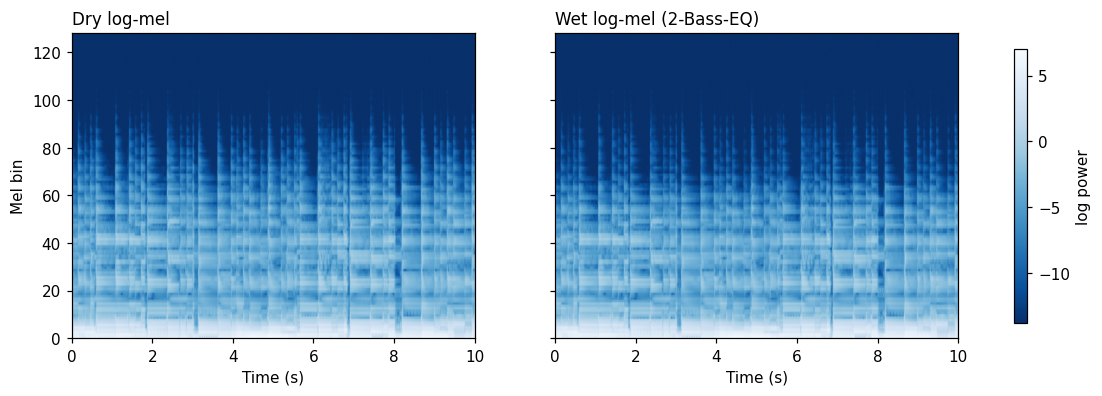

In [21]:
from fxp1.features import LogMelExtractor
from fxp1.common import expected_num_frames
_lm = LogMelExtractor(CFG).to(DEVICE)
with torch.no_grad():
    mel_pair = _lm.raw_log_mel(torch.from_numpy(np.stack([dry0, wet0])).to(DEVICE)).cpu().numpy()
print("Log-Mel shape [2 (dry, wet), n_mels, T]:", mel_pair.shape, "| expected T =", expected_num_frames(CFG))
assert mel_pair.shape == (2, CFG["N_MELS"], expected_num_frames(CFG))

fig, axes = plt.subplots(1, 2, figsize=(13, 3.6), dpi=110, sharey=True)
vmin, vmax = np.percentile(mel_pair, 5), mel_pair.max()
for ax, m, title in zip(axes, mel_pair, ["Dry log-mel", f"Wet log-mel ({_ex.get('sample_id', '')})"]):
    im = ax.imshow(m, origin="lower", aspect="auto", cmap="Blues_r", vmin=vmin, vmax=vmax,
                   extent=[0, CFG["AUDIO_LENGTH_SECONDS"], 0, CFG["N_MELS"]])
    ax.set_title(title, loc="left", fontsize=11); ax.set_xlabel("Time (s)")
axes[0].set_ylabel("Mel bin")
fig.colorbar(im, ax=axes, label="log power", shrink=0.9)
plt.show()
del _lm

## 12. Dataset / DataLoader
* `FXPairDataset` keeps only `dry_audio`, `wet_audio`, the 3 label columns and `sample_id`; everything else
  (effect chain, parameters, combination strings) is dropped before any example is built — a hard guard asserts it.
* Audio is decoded lazily in DataLoader workers (`num_workers`, `pin_memory` configurable).
* Training: `DistributedSampler` (shuffled, seeded, `set_epoch`). Validation/test: a non-padded shard per rank, so each
  example is evaluated exactly once; predictions are gathered and re-sorted by index.
* Normalisation stats (one global mean/std for log-mel, dry+wet pooled) are estimated here from **training** audio only.

In [22]:
%%writefile {PKG_DIR}/data.py
"""Hugging Face dataset loading + PyTorch Dataset / DataLoader layer.

* The dataset is loaded with `datasets.load_dataset` (parquet shards are
  downloaded once to the HF cache and memory-mapped by Arrow -> the audio is
  NOT loaded into RAM).
* Audio columns are cast to `Audio(decode=False)` so each row yields raw WAV
  bytes; decoding is done by `AudioPreprocessor` inside DataLoader workers
  (soundfile; no torchcodec/ffmpeg dependency, fork-safe on Kaggle).
* Only `dry_audio`, `wet_audio`, the three label columns and `sample_id` are
  kept. effect_chain / parameters / combination strings are dropped before
  any example is produced, so they can never become model inputs.
"""
from __future__ import annotations

import random
from typing import Any, Dict, List, Optional

import numpy as np
import torch
from torch.utils.data import DataLoader, Dataset, Sampler
from torch.utils.data.distributed import DistributedSampler

from .audio import AudioPreprocessor
from .common import FORBIDDEN_INPUT_COLUMNS


def load_hf_splits(cfg: Dict[str, Any], splits=("train", "validation")):
    """Load the requested splits of the existing dataset (never regenerated)."""
    from datasets import load_dataset

    kwargs = {}
    if cfg.get("HF_DATASET_REVISION"):
        kwargs["revision"] = cfg["HF_DATASET_REVISION"]
    if cfg.get("HF_DATASETS_CACHE"):
        kwargs["cache_dir"] = cfg["HF_DATASETS_CACHE"]
    if cfg.get("HF_DATASET_LOCAL_PATH"):  # optional: local copy / testing
        ds = load_dataset(cfg["HF_DATASET_LOCAL_PATH"], **kwargs)
    else:
        ds = load_dataset(cfg["HF_DATASET_ID"], **kwargs)
    out = {}
    for split in splits:
        if split not in ds:
            raise KeyError(f"Split '{split}' not found. Available: {list(ds.keys())}")
        out[split] = prepare_split(ds[split], cfg)
    return out


def prepare_split(split_ds, cfg: Dict[str, Any]):
    from datasets import Audio

    keep = [cfg["DRY_AUDIO_COLUMN"], cfg["WET_AUDIO_COLUMN"], *cfg["LABEL_COLUMNS"]]
    if cfg.get("ID_COLUMN") in split_ds.column_names:
        keep.append(cfg["ID_COLUMN"])
    missing = [c for c in keep if c not in split_ds.column_names]
    if missing:
        raise KeyError(f"Missing columns {missing}; found {split_ds.column_names}")
    leaked = set(keep) & set(FORBIDDEN_INPUT_COLUMNS)
    assert not leaked, f"Forbidden metadata columns selected as inputs: {leaked}"
    split_ds = split_ds.select_columns(keep)
    for col in (cfg["DRY_AUDIO_COLUMN"], cfg["WET_AUDIO_COLUMN"]):
        split_ds = split_ds.cast_column(col, Audio(decode=False))
    return split_ds


class FXPairDataset(Dataset):
    """Yields {'dry': [N], 'wet': [N], 'labels': [3], 'index': int}."""

    def __init__(self, hf_split, cfg: Dict[str, Any]):
        self.ds = hf_split
        self.dry_col = cfg["DRY_AUDIO_COLUMN"]
        self.wet_col = cfg["WET_AUDIO_COLUMN"]
        self.label_cols = list(cfg["LABEL_COLUMNS"])
        self.id_col = cfg.get("ID_COLUMN")
        self.pre = AudioPreprocessor(cfg)
        # Labels are tiny: read once (no audio decoded here).
        # list(...) also handles datasets>=4, where ds["col"] is a lazy Column object.
        lab = np.stack([np.asarray(list(hf_split[c]), dtype=np.float32) for c in self.label_cols], axis=1)
        if not np.isin(lab, (0.0, 1.0)).all():
            raise ValueError("Label columns must be binary 0/1.")
        if (lab.sum(axis=1) == 0).any():
            raise ValueError("Found an example with no effect; Phase 1 expects 7 non-empty combinations.")
        self.labels = lab
        self.ids: Optional[List[str]] = (list(hf_split[self.id_col])
                                         if self.id_col in hf_split.column_names else None)

    def __len__(self) -> int:
        return len(self.ds)

    def __getitem__(self, idx: int) -> Dict[str, Any]:
        row = self.ds[int(idx)]
        dry = self.pre(row[self.dry_col])
        wet = self.pre(row[self.wet_col])
        return {
            "dry": torch.from_numpy(dry),
            "wet": torch.from_numpy(wet),
            "labels": torch.from_numpy(self.labels[int(idx)].copy()),
            "index": int(idx),
        }


class ShardSampler(Sampler):
    """Deterministic, non-padded, non-shuffled shard for distributed eval.

    Rank r gets indices r, r+W, r+2W, ...  Every example is evaluated exactly
    once across ranks (unlike DistributedSampler, which pads with duplicates).
    """

    def __init__(self, length: int, rank: int, world_size: int):
        self.indices = list(range(rank, length, world_size))

    def __iter__(self):
        return iter(self.indices)

    def __len__(self) -> int:
        return len(self.indices)


def _seed_worker(worker_id: int) -> None:
    seed = torch.initial_seed() % 2**32
    np.random.seed(seed)
    random.seed(seed)


def build_loader(dataset: FXPairDataset, cfg: Dict[str, Any], train: bool,
                 rank: int = 0, world_size: int = 1, num_workers: Optional[int] = None,
                 batch_size: Optional[int] = None) -> DataLoader:
    nw = int(cfg["NUM_WORKERS"] if num_workers is None else num_workers)
    bs = int(batch_size or (cfg["BATCH_SIZE"] if train else cfg["EVAL_BATCH_SIZE"]))
    if train:
        sampler = DistributedSampler(dataset, num_replicas=world_size, rank=rank,
                                     shuffle=True, seed=int(cfg["SEED"]), drop_last=False)
    else:
        sampler = ShardSampler(len(dataset), rank, world_size)
    gen = torch.Generator()
    gen.manual_seed(int(cfg["SEED"]) + rank)
    return DataLoader(
        dataset, batch_size=bs, sampler=sampler, num_workers=nw,
        pin_memory=bool(cfg["PIN_MEMORY"]) and torch.cuda.is_available(),
        drop_last=False, worker_init_fn=_seed_worker, generator=gen,
        persistent_workers=(nw > 0 and bool(cfg.get("PERSISTENT_WORKERS", True))),
        prefetch_factor=(int(cfg.get("PREFETCH_FACTOR", 2)) if nw > 0 else None),
    )

Writing /kaggle/working/fxp1/data.py


In [23]:
from fxp1.data import FXPairDataset, build_loader, prepare_split
from fxp1.features import compute_norm_stats

train_split = prepare_split(raw["train"], CFG)
val_split = prepare_split(raw["validation"], CFG)
train_ds, val_ds = FXPairDataset(train_split, CFG), FXPairDataset(val_split, CFG)
print(f"train={len(train_ds)}  validation={len(val_ds)}  (test is NOT loaded until Section 24)")
print("Columns visible to the Dataset:", train_split.column_names)

_loader = build_loader(train_ds, CFG, train=True, num_workers=0)
batch = next(iter(_loader))
print({k: (tuple(v.shape), str(v.dtype)) for k, v in batch.items() if hasattr(v, "shape")})
print("labels of first batch [EQ, Comp, Rev]:\n", batch["labels"].int().numpy())
print(f"steps/epoch per GPU with {NPROC} process(es): {int(np.ceil(np.ceil(len(train_ds) / NPROC) / CFG['BATCH_SIZE']))}")

if CFG["NORM_MEAN"] is None or CFG["NORM_STD"] is None:
    t0 = time.time()
    stats = compute_norm_stats(train_ds, CFG, DEVICE)
    CFG["NORM_MEAN"], CFG["NORM_STD"] = stats["NORM_MEAN"], stats["NORM_STD"]
    save_config()
    print(f"Log-mel normalisation from {CFG['NORM_STATS_NUM_EXAMPLES']} training clips: mean={CFG['NORM_MEAN']:.4f} "
          f"std={CFG['NORM_STD']:.4f} ({time.time() - t0:.1f}s) -> saved to config")
else:
    print(f"Using configured normalisation: mean={CFG['NORM_MEAN']}, std={CFG['NORM_STD']}")

train=2191  validation=483  (test is NOT loaded until Section 24)
Columns visible to the Dataset: ['dry_audio', 'wet_audio', 'eq_label', 'compressor_label', 'reverb_label', 'sample_id']
{'dry': ((16, 441000), 'torch.float32'), 'wet': ((16, 441000), 'torch.float32'), 'labels': ((16, 3), 'torch.float32'), 'index': ((16,), 'torch.int64')}
labels of first batch [EQ, Comp, Rev]:
 [[0 1 0]
 [1 1 1]
 [1 0 1]
 [1 1 0]
 [0 1 1]
 [0 1 1]
 [0 1 0]
 [0 1 1]
 [1 0 1]
 [0 1 1]
 [1 0 0]
 [1 1 1]
 [1 0 0]
 [1 0 0]
 [0 1 0]
 [0 1 0]]
steps/epoch per GPU with 2 process(es): 69
Log-mel normalisation from 128 training clips: mean=-6.3604 std=4.8448 (0.6s) -> saved to config


## 13. Transformer Model
| stage | operation | shape (B = batch) |
|---|---|---|
| inputs | dry, wet waveforms | `[B, 441000]` each |
| Log-Mel | per signal, shared config | `[B, 128, 862]` each |
| **Feature fusion** | transpose to `[B, T, M]`, **concatenate on the feature axis** (frame *t* of dry ‖ frame *t* of wet) | `[B, 862, 256]` |
| projection | explicit `Linear(256 → d_model)` + LayerNorm | `[B, 862, 256]` |
| tokens | prepend learned **[CLS]**, add sinusoidal positions, dropout | `[B, 863, 256]` |
| Transformer encoder | 4 × pre-LN layers (4 heads, FF 512, GELU, dropout 0.1) + final LayerNorm | `[B, 863, 256]` |
| pooling | **[CLS] token** (position 0) | `[B, 256]` |
| head | Linear(256→128) → GELU → Dropout → Linear(128→3) | `[B, 3]` logits = `[EQ, Compressor, Reverb]` |

In [24]:
%%writefile {PKG_DIR}/model.py
"""Log-Mel + Transformer effect-type classifier.

    dry [B, N] --LogMel--> [B, M, T] --transpose--> [B, T, M] --+
                                                                 +-- concat on feature axis --> [B, T, 2M]
    wet [B, N] --LogMel--> [B, M, T] --transpose--> [B, T, M] --+        (FUSION="concat")
                                                                          |
                                     Linear(2M -> d_model) + LayerNorm    v   [B, T, d_model]
                         prepend learned [CLS] token, + sinusoidal pos.   ->  [B, T+1, d_model]
                         TransformerEncoder (pre-LN, GELU, batch_first)   ->  [B, T+1, d_model]
                         take position 0 ([CLS] pooling)                  ->  [B, d_model]
                         head: Linear -> GELU -> Dropout -> Linear        ->  [B, 3] logits
                                                               [EQ, Compressor, Reverb]

Frame t of the dry signal is aligned with frame t of the wet signal (same
STFT grid), so concatenation fuses time-aligned dry/wet spectra per token.
Optional FUSION="concat_diff" appends (wet - dry) -> [B, T, 3M]; the
default for this experiment is plain "concat".
"""
from __future__ import annotations

import math
from typing import Any, Dict

import torch
import torch.nn as nn

from .common import EFFECTS, expected_num_frames, fused_feature_dim
from .features import LogMelExtractor


def sinusoidal_positions(length: int, dim: int) -> torch.Tensor:
    pos = torch.arange(length, dtype=torch.float32).unsqueeze(1)
    div = torch.exp(torch.arange(0, dim, 2, dtype=torch.float32) * (-math.log(10000.0) / dim))
    pe = torch.zeros(length, dim)
    pe[:, 0::2] = torch.sin(pos * div)
    pe[:, 1::2] = torch.cos(pos * div[: pe[:, 1::2].shape[1]])
    return pe.unsqueeze(0)  # [1, length, dim]


class FXEffectTransformer(nn.Module):
    def __init__(self, cfg: Dict[str, Any]):
        super().__init__()
        d_model = int(cfg["D_MODEL"])
        self.fusion = cfg["FUSION"]
        self.logmel = LogMelExtractor(cfg)
        self.num_frames = expected_num_frames(cfg)
        in_dim = fused_feature_dim(cfg)

        self.input_proj = nn.Linear(in_dim, d_model)          # explicit fusion projection
        self.input_norm = nn.LayerNorm(d_model)
        self.cls_token = nn.Parameter(torch.zeros(1, 1, d_model))
        nn.init.trunc_normal_(self.cls_token, std=0.02)
        self.register_buffer("pos_embed", sinusoidal_positions(self.num_frames + 1, d_model),
                             persistent=False)
        self.input_dropout = nn.Dropout(float(cfg["DROPOUT"]))

        layer = nn.TransformerEncoderLayer(
            d_model=d_model, nhead=int(cfg["N_HEAD"]), dim_feedforward=int(cfg["DIM_FEEDFORWARD"]),
            dropout=float(cfg["DROPOUT"]), activation="gelu", batch_first=True, norm_first=True,
        )
        self.encoder = nn.TransformerEncoder(layer, num_layers=int(cfg["NUM_LAYERS"]),
                                             norm=nn.LayerNorm(d_model), enable_nested_tensor=False)
        hidden = int(cfg["HEAD_HIDDEN_DIM"])
        self.head = nn.Sequential(
            nn.Linear(d_model, hidden), nn.GELU(), nn.Dropout(float(cfg["HEAD_DROPOUT"])),
            nn.Linear(hidden, len(EFFECTS)),
        )

    def fuse(self, dry_mel: torch.Tensor, wet_mel: torch.Tensor) -> torch.Tensor:
        """[B, M, T] x 2 -> [B, T, 2M] (or [B, T, 3M] for concat_diff)."""
        dry_t, wet_t = dry_mel.transpose(1, 2), wet_mel.transpose(1, 2)
        parts = [dry_t, wet_t] + ([wet_t - dry_t] if self.fusion == "concat_diff" else [])
        return torch.cat(parts, dim=-1)

    def forward(self, dry: torch.Tensor, wet: torch.Tensor, return_shapes: bool = False):
        shapes = {"dry_wave": tuple(dry.shape), "wet_wave": tuple(wet.shape)}
        dry_mel = self.logmel(dry)                                  # [B, M, T]
        wet_mel = self.logmel(wet)                                  # [B, M, T]
        fused = self.fuse(dry_mel, wet_mel)                         # [B, T, 2M]
        x = self.input_norm(self.input_proj(fused))                 # [B, T, D]
        b, t, _ = x.shape
        if t + 1 > self.pos_embed.shape[1]:
            raise ValueError(f"Sequence length {t} exceeds configured {self.num_frames} frames.")
        x = torch.cat([self.cls_token.expand(b, -1, -1).to(x.dtype), x], dim=1)  # [B, T+1, D]
        x = self.input_dropout(x + self.pos_embed[:, : t + 1].to(x.dtype))
        enc = self.encoder(x)                                       # [B, T+1, D]
        pooled = enc[:, 0]                                          # [B, D]  ([CLS])
        logits = self.head(pooled)                                  # [B, 3]
        if return_shapes:
            shapes.update({
                "dry_log_mel": tuple(dry_mel.shape), "wet_log_mel": tuple(wet_mel.shape),
                "fused": tuple(fused.shape), "projected": (b, t, x.shape[-1]),
                "transformer_in": tuple(x.shape), "transformer_out": tuple(enc.shape),
                "pooled_cls": tuple(pooled.shape), "logits": tuple(logits.shape),
            })
            return logits, shapes
        return logits


def build_model(cfg: Dict[str, Any]) -> FXEffectTransformer:
    return FXEffectTransformer(cfg)


def count_parameters(model: nn.Module) -> int:
    return sum(p.numel() for p in model.parameters() if p.requires_grad)


def unwrap(model: nn.Module) -> nn.Module:
    return model.module if hasattr(model, "module") else model

Writing /kaggle/working/fxp1/model.py


In [25]:
from fxp1.model import build_model, count_parameters
model = build_model(CFG)
model.logmel.set_normalization(CFG["NORM_MEAN"], CFG["NORM_STD"])
model.to(DEVICE).eval()
N_PARAMS = count_parameters(model)
with torch.no_grad():
    _logits, SHAPES = model(batch["dry"].to(DEVICE), batch["wet"].to(DEVICE), return_shapes=True)
print(f"Trainable parameters: {N_PARAMS:,}")
display(pd.DataFrame({"shape": {k: str(v) for k, v in SHAPES.items()}}))
assert SHAPES["logits"] == (batch["dry"].shape[0], 3)

Trainable parameters: 2,208,771


,shape
dry_wave,"(16, 441000)"
wet_wave,"(16, 441000)"
dry_log_mel,"(16, 128, 862)"
wet_log_mel,"(16, 128, 862)"
fused,"(16, 862, 256)"
projected,"(16, 862, 256)"
transformer_in,"(16, 863, 256)"
transformer_out,"(16, 863, 256)"
pooled_cls,"(16, 256)"
logits,"(16, 3)"


## 14. Loss and Metrics
**Loss:** `nn.BCEWithLogitsLoss()` on the 3 logits (mean over batch × 3). No softmax / CrossEntropy over 7 classes.

**Metrics** (threshold `THRESHOLD`, default `p ≥ 0.5`): per-effect precision / recall / F1, micro F1, macro F1,
exact-match accuracy (all 3 bits right), and **7-combination accuracy** — the thresholded vector is read as one of the 7
combinations (e.g. `[1,0,1] → EQ + Reverb`); the only invalid vector `[0,0,0]` is mapped to the single most probable
effect, and the number of such cases is reported. The 7×7 confusion matrix uses the same mapping.

In [26]:
%%writefile {PKG_DIR}/metrics.py
"""Multi-label metrics for [EQ, Compressor, Reverb] + 7-combination reporting.

Definitions (threshold t, default 0.5, applied to sigmoid probabilities):
    pred_k = 1[p_k >= t]
    per-effect precision / recall / F1   (zero_division -> 0)
    micro F1  = F1 over pooled TP/FP/FN of the 3 effects
    macro F1  = unweighted mean of the 3 per-effect F1 scores
    exact-match accuracy = fraction of clips whose thresholded 3-bit vector
                           equals the ground-truth vector exactly
    7-combination accuracy = fraction whose predicted *valid* combination
                           equals the true combination. The thresholded vector
                           is mapped to one of the 7 combinations; the only
                           invalid vector, [0,0,0], is mapped to the single
                           most probable effect (argmax p_k). So exact-match
                           and combination accuracy differ only on [0,0,0]
                           predictions (counted in `num_all_zero_predictions`).
"""
from __future__ import annotations

from typing import Any, Dict, Optional

import numpy as np

from .common import COMBINATION_NAMES, EFFECTS, VECTOR_TO_COMBINATION


def sigmoid(x: np.ndarray) -> np.ndarray:
    return 1.0 / (1.0 + np.exp(-x))


def vectors_to_combination_index(vectors: np.ndarray) -> np.ndarray:
    return np.array([VECTOR_TO_COMBINATION[tuple(int(v) for v in row)] for row in vectors], dtype=np.int64)


def predict_valid_vectors(probs: np.ndarray, threshold: float) -> Dict[str, np.ndarray]:
    raw = (probs >= threshold).astype(np.int64)
    valid = raw.copy()
    all_zero = valid.sum(axis=1) == 0
    if all_zero.any():
        valid[all_zero, probs[all_zero].argmax(axis=1)] = 1
    return {"raw": raw, "valid": valid, "all_zero": all_zero}


def _prf(tp: float, fp: float, fn: float):
    p = tp / (tp + fp) if (tp + fp) > 0 else 0.0
    r = tp / (tp + fn) if (tp + fn) > 0 else 0.0
    f = 2 * p * r / (p + r) if (p + r) > 0 else 0.0
    return p, r, f


def compute_metrics(logits: np.ndarray, targets: np.ndarray, threshold: float = 0.5,
                    loss: Optional[float] = None) -> Dict[str, Any]:
    logits = np.asarray(logits, dtype=np.float64)
    targets = np.asarray(targets).astype(np.int64)
    probs = sigmoid(logits)
    pv = predict_valid_vectors(probs, threshold)
    preds = pv["raw"]

    out: Dict[str, Any] = {"num_examples": int(len(targets)), "threshold": float(threshold)}
    if loss is not None:
        out["loss"] = float(loss)

    tps, fps, fns, f1s = 0, 0, 0, []
    for k, name in enumerate(EFFECTS):
        tp = int(((preds[:, k] == 1) & (targets[:, k] == 1)).sum())
        fp = int(((preds[:, k] == 1) & (targets[:, k] == 0)).sum())
        fn = int(((preds[:, k] == 0) & (targets[:, k] == 1)).sum())
        p, r, f = _prf(tp, fp, fn)
        out[f"{name}/precision"], out[f"{name}/recall"], out[f"{name}/f1"] = p, r, f
        out[f"{name}/support"] = int(targets[:, k].sum())
        tps, fps, fns = tps + tp, fps + fp, fns + fn
        f1s.append(f)
    out["micro_precision"], out["micro_recall"], out["micro_f1"] = _prf(tps, fps, fns)
    out["macro_f1"] = float(np.mean(f1s))
    out["macro_precision"] = float(np.mean([out[f"{e}/precision"] for e in EFFECTS]))
    out["macro_recall"] = float(np.mean([out[f"{e}/recall"] for e in EFFECTS]))
    out["exact_match_accuracy"] = float((preds == targets).all(axis=1).mean()) if len(targets) else 0.0

    true_idx = vectors_to_combination_index(targets)
    pred_idx = vectors_to_combination_index(pv["valid"])
    out["combination_accuracy"] = float((true_idx == pred_idx).mean()) if len(targets) else 0.0
    out["num_all_zero_predictions"] = int(pv["all_zero"].sum())
    n_cls = len(COMBINATION_NAMES)
    cm = np.zeros((n_cls, n_cls), dtype=np.int64)
    for t, p in zip(true_idx, pred_idx):
        cm[t, p] += 1
    out["confusion_matrix"] = cm.tolist()           # rows = true, cols = predicted
    out["confusion_matrix_labels"] = list(COMBINATION_NAMES)
    out["per_combination_accuracy"] = {
        COMBINATION_NAMES[i]: (float(cm[i, i] / cm[i].sum()) if cm[i].sum() else None) for i in range(n_cls)
    }
    return out


SCALAR_KEYS_FOR_LOGGING = (
    "loss", "macro_f1", "micro_f1", "exact_match_accuracy", "combination_accuracy",
    "macro_precision", "macro_recall", "num_all_zero_predictions",
)

Writing /kaggle/working/fxp1/metrics.py


In [27]:
from fxp1.metrics import compute_metrics
criterion = nn.BCEWithLogitsLoss()
_demo = compute_metrics(np.array([[3., -3, 3], [-1, -2, -0.5], [2, 2, -2]]), np.array([[1, 0, 1], [0, 0, 1], [1, 0, 0]]))
print("demo: exact-match", _demo["exact_match_accuracy"], "| 7-comb", _demo["combination_accuracy"],
      "| all-zero preds", _demo["num_all_zero_predictions"], "| macro F1", round(_demo["macro_f1"], 3))
print("Combinations:", [f"{i + 1}. {n} {list(v)}" for i, (n, v) in enumerate(COMBINATIONS)])

demo: exact-match 0.3333333333333333 | 7-comb 0.6666666666666666 | all-zero preds 1 | macro F1 0.556
Combinations: ['1. EQ [1, 0, 0]', '2. Compressor [0, 1, 0]', '3. Reverb [0, 0, 1]', '4. EQ + Compressor [1, 1, 0]', '5. EQ + Reverb [1, 0, 1]', '6. Compressor + Reverb [0, 1, 1]', '7. EQ + Compressor + Reverb [1, 1, 1]']


## 15. Optimizer and Scheduler
AdamW (no weight decay on biases / LayerNorm / [CLS]); per-step linear warm-up then cosine decay; FP16 `torch.amp` autocast + `GradScaler` on CUDA.

In [28]:
%%writefile {PKG_DIR}/optim.py
"""Optimizer, LR scheduler and AMP helpers.

Optimizer : AdamW; weight decay on Linear weights only (no decay on biases,
            LayerNorm weights, [CLS] token).
Scheduler : per-optimizer-step LambdaLR = linear warmup (WARMUP_EPOCHS) then
            cosine decay to MIN_LR_RATIO * LEARNING_RATE at NUM_EPOCHS.
AMP       : torch.amp.autocast(float16) + GradScaler on CUDA (T4 has no bf16).
"""
from __future__ import annotations

import math
from contextlib import nullcontext
from typing import Any, Dict

import torch
import torch.nn as nn


def build_optimizer(model: nn.Module, cfg: Dict[str, Any]) -> torch.optim.Optimizer:
    decay, no_decay = [], []
    for name, p in model.named_parameters():
        if not p.requires_grad:
            continue
        if p.ndim < 2 or "norm" in name.lower() or name.endswith("cls_token"):
            no_decay.append(p)
        else:
            decay.append(p)
    groups = [
        {"params": decay, "weight_decay": float(cfg["WEIGHT_DECAY"])},
        {"params": no_decay, "weight_decay": 0.0},
    ]
    return torch.optim.AdamW(groups, lr=float(cfg["LEARNING_RATE"]),
                             betas=tuple(cfg["ADAM_BETAS"]), eps=float(cfg["ADAM_EPS"]))


def build_scheduler(optimizer: torch.optim.Optimizer, cfg: Dict[str, Any], steps_per_epoch: int):
    total = max(1, int(cfg["NUM_EPOCHS"]) * steps_per_epoch)
    warmup = int(round(float(cfg["WARMUP_EPOCHS"]) * steps_per_epoch))
    min_ratio = float(cfg["MIN_LR_RATIO"])

    def lr_lambda(step: int) -> float:
        if warmup > 0 and step < warmup:
            return (step + 1) / warmup
        progress = min(1.0, (step - warmup) / max(1, total - warmup))
        return min_ratio + (1.0 - min_ratio) * 0.5 * (1.0 + math.cos(math.pi * progress))

    sched = torch.optim.lr_scheduler.LambdaLR(optimizer, lr_lambda)
    sched_info = {"type": "linear_warmup_cosine", "total_steps": total, "warmup_steps": warmup,
                  "min_lr_ratio": min_ratio, "steps_per_epoch": steps_per_epoch, "step_unit": "optimizer step"}
    return sched, sched_info


def make_grad_scaler(enabled: bool):
    try:
        return torch.amp.GradScaler("cuda", enabled=enabled)
    except (AttributeError, TypeError):  # older PyTorch
        return torch.cuda.amp.GradScaler(enabled=enabled)


def autocast_ctx(device: torch.device, enabled: bool):
    if not enabled:
        return nullcontext()
    return torch.autocast(device_type=device.type, dtype=torch.float16, enabled=True)


def optimizer_config(cfg: Dict[str, Any]) -> Dict[str, Any]:
    return {"type": "AdamW", "lr": cfg["LEARNING_RATE"], "weight_decay": cfg["WEIGHT_DECAY"],
            "betas": cfg["ADAM_BETAS"], "eps": cfg["ADAM_EPS"],
            "gradient_clipping": cfg["GRADIENT_CLIPPING"],
            "no_decay": "biases, LayerNorm weights, cls_token"}

Writing /kaggle/working/fxp1/optim.py


optimizer: {'type': 'AdamW', 'lr': 0.0003, 'weight_decay': 0.05, 'betas': [0.9, 0.98], 'eps': 1e-08, 'gradient_clipping': 1.0, 'no_decay': 'biases, LayerNorm weights, cls_token'}
scheduler: {'type': 'linear_warmup_cosine', 'total_steps': 2760, 'warmup_steps': 138, 'min_lr_ratio': 0.02, 'steps_per_epoch': 69, 'step_unit': 'optimizer step'}


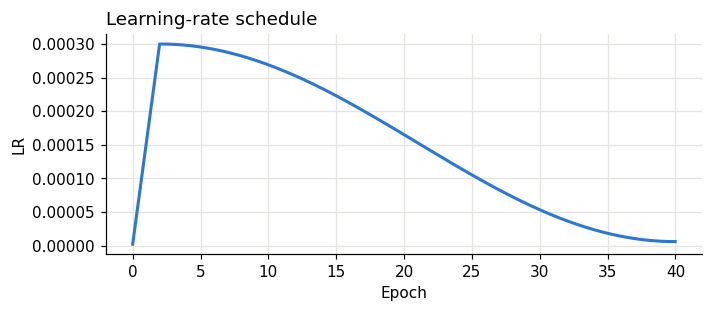

In [29]:
from fxp1.optim import build_optimizer, build_scheduler, optimizer_config
_steps = int(np.ceil(np.ceil(len(train_ds) / NPROC) / CFG["BATCH_SIZE"]))
_opt = build_optimizer(model, CFG)
_sched, SCHED_INFO = build_scheduler(_opt, CFG, _steps)
lrs = []
for _ in range(SCHED_INFO["total_steps"]):
    lrs.append(_opt.param_groups[0]["lr"]); _opt.step(); _sched.step()
print("optimizer:", optimizer_config(CFG)); print("scheduler:", SCHED_INFO)
fig, ax = plt.subplots(figsize=(7, 2.6), dpi=110)
ax.plot(np.arange(len(lrs)) / _steps, lrs, color="#2a78d6", linewidth=2)
ax.set_title("Learning-rate schedule", loc="left"); ax.set_xlabel("Epoch"); ax.set_ylabel("LR")
ax.grid(color="#e4e3df"); [ax.spines[s].set_visible(False) for s in ("top", "right")]
plt.show()
del _opt, _sched

## 16. TensorBoard Setup
Rank 0 writes to `runs/phase1_logmel_transformer/`:
`train/loss`, `validation/loss`, `validation/macro_f1`, `validation/micro_f1`, `validation/exact_match_accuracy`,
`validation/combination_accuracy`, `{EQ,Compressor,Reverb}/{precision,recall,f1}` (x-axis = epoch), plus
`train/loss_step`, `learning_rate`, `global_step` (x-axis = global step) and `epoch`.
The event files are pushed to the Hub with every checkpoint (the model page then shows a **Training metrics** tab) and
restored automatically on resume. This section also writes the reporting utilities (history CSV/JSON, plots, model card).

In [30]:
%%writefile {PKG_DIR}/reporting.py
"""Training history files, plots and the Hugging Face model card."""
from __future__ import annotations

import json
import os
from typing import Any, Dict, List, Optional

import numpy as np

from .common import COMBINATION_NAMES, COMBINATIONS, EFFECTS, atomic_write_json, atomic_write_text

HISTORY_COLUMNS = [
    "epoch", "global_step", "train_loss", "validation_loss", "validation_macro_f1",
    "validation_micro_f1", "validation_accuracy", "validation_combination_accuracy",
    "learning_rate", "EQ_precision", "EQ_recall", "EQ_f1", "Compressor_precision",
    "Compressor_recall", "Compressor_f1", "Reverb_precision", "Reverb_recall", "Reverb_f1",
    "validation_all_zero_predictions", "epoch_time_s", "is_best",
]

# Chart styling: validated reference palette, recessive axes/grid, thin marks.
SERIES = ["#2a78d6", "#eb6834"]           # categorical slots 1-2 (blue, orange)
TEXT_PRIMARY, TEXT_SECONDARY, GRID = "#0b0b0b", "#52514e", "#e4e3df"
SEQ_BLUE = ["#ffffff", "#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"]


def save_history(history: List[Dict[str, Any]], results_dir: str) -> Dict[str, str]:
    import pandas as pd

    os.makedirs(results_dir, exist_ok=True)
    rows = [{c: h.get(c) for c in HISTORY_COLUMNS} for h in history]
    csv_path = os.path.join(results_dir, "training_history.csv")
    json_path = os.path.join(results_dir, "training_history.json")
    atomic_write_text(csv_path, pd.DataFrame(rows, columns=HISTORY_COLUMNS).to_csv(index=False))
    atomic_write_json(json_path, history)
    return {"csv": csv_path, "json": json_path}


def _style(ax, title: str, ylabel: str):
    ax.set_title(title, loc="left", fontsize=12, color=TEXT_PRIMARY, pad=10)
    ax.set_xlabel("Epoch", color=TEXT_SECONDARY)
    ax.set_ylabel(ylabel, color=TEXT_SECONDARY)
    ax.grid(True, color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    for side in ("left", "bottom"):
        ax.spines[side].set_color(GRID)
    ax.tick_params(colors=TEXT_SECONDARY, labelsize=9)


def _line_plot(path: str, epochs, series: Dict[str, List[float]], title: str, ylabel: str,
               best_epoch: Optional[int] = None, ylim=None) -> str:
    import matplotlib
    matplotlib.use("Agg")
    import matplotlib.pyplot as plt

    fig, ax = plt.subplots(figsize=(7.5, 4.2), dpi=130)
    for i, (name, values) in enumerate(series.items()):
        ax.plot(epochs, values, color=SERIES[i], linewidth=2, label=name,
                marker="o" if len(epochs) <= 30 else None, markersize=4)
    if best_epoch is not None:
        ax.axvline(best_epoch, color=TEXT_SECONDARY, linewidth=1, linestyle="--")
        ax.annotate(f"best (epoch {best_epoch})", xy=(best_epoch, 1), xycoords=("data", "axes fraction"),
                    xytext=(4, -12), textcoords="offset points", fontsize=8, color=TEXT_SECONDARY)
    if ylim:
        ax.set_ylim(*ylim)
    _style(ax, title, ylabel)
    if len(series) > 1:
        ax.legend(frameon=False, fontsize=9, labelcolor=TEXT_PRIMARY)
    fig.tight_layout()
    fig.savefig(path)
    plt.close(fig)
    return path


def plot_training_curves(history: List[Dict[str, Any]], plots_dir: str) -> List[str]:
    os.makedirs(plots_dir, exist_ok=True)
    if not history:
        return []
    ep = [h["epoch"] for h in history]
    best = [h["epoch"] for h in history if h.get("is_best")]
    best_epoch = best[-1] if best else None
    return [
        _line_plot(os.path.join(plots_dir, "loss_train_vs_validation.png"), ep,
                   {"Train loss": [h["train_loss"] for h in history],
                    "Validation loss": [h["validation_loss"] for h in history]},
                   "Train vs validation loss (BCEWithLogits)", "Loss", best_epoch),
        _line_plot(os.path.join(plots_dir, "validation_macro_f1.png"), ep,
                   {"Validation macro F1": [h["validation_macro_f1"] for h in history]},
                   "Validation macro F1", "Macro F1", best_epoch, (0, 1.02)),
        _line_plot(os.path.join(plots_dir, "validation_micro_f1.png"), ep,
                   {"Validation micro F1": [h["validation_micro_f1"] for h in history]},
                   "Validation micro F1", "Micro F1", best_epoch, (0, 1.02)),
        _line_plot(os.path.join(plots_dir, "validation_exact_match_accuracy.png"), ep,
                   {"Validation exact-match accuracy": [h["validation_accuracy"] for h in history]},
                   "Validation exact-match accuracy", "Accuracy", best_epoch, (0, 1.02)),
    ]


def plot_confusion_matrix(cm, path: str, title: str = "Test set: 7-combination confusion matrix") -> str:
    import matplotlib
    matplotlib.use("Agg")
    import matplotlib.pyplot as plt
    from matplotlib.colors import LinearSegmentedColormap

    cm = np.asarray(cm)
    cmap = LinearSegmentedColormap.from_list("seq_blue", SEQ_BLUE)
    fig, ax = plt.subplots(figsize=(8.2, 7.0), dpi=130)
    vmax = max(1, int(cm.max()))
    ax.imshow(cm, cmap=cmap, vmin=0, vmax=vmax)
    n = len(COMBINATION_NAMES)
    for i in range(n):
        for j in range(n):
            val = int(cm[i, j])
            frac = val / vmax
            ax.text(j, i, str(val), ha="center", va="center", fontsize=10,
                    color="#ffffff" if frac > 0.55 else TEXT_PRIMARY)
    ax.set_xticks(range(n))
    ax.set_yticks(range(n))
    ax.set_xticklabels(COMBINATION_NAMES, rotation=35, ha="right", fontsize=9, color=TEXT_PRIMARY)
    ax.set_yticklabels(COMBINATION_NAMES, fontsize=9, color=TEXT_PRIMARY)
    ax.set_xlabel("Predicted combination", color=TEXT_SECONDARY)
    ax.set_ylabel("True combination", color=TEXT_SECONDARY)
    ax.set_title(title, loc="left", fontsize=12, color=TEXT_PRIMARY, pad=10)
    ax.set_xticks(np.arange(-0.5, n, 1), minor=True)
    ax.set_yticks(np.arange(-0.5, n, 1), minor=True)
    ax.grid(which="minor", color="#ffffff", linewidth=2)
    ax.tick_params(which="minor", length=0)
    for s in ax.spines.values():
        s.set_visible(False)
    fig.tight_layout()
    fig.savefig(path)
    plt.close(fig)
    return path


def _fmt(v, nd=4):
    return "—" if v is None else (f"{v:.{nd}f}" if isinstance(v, float) else str(v))


def build_model_card(cfg: Dict[str, Any], history: List[Dict[str, Any]], best_state: Dict[str, Any],
                     test_metrics: Optional[Dict[str, Any]], shapes: Dict[str, Any], n_params: int) -> str:
    best_row = next((h for h in history if h["epoch"] == best_state.get("best_epoch")), None)
    tm = test_metrics or {}
    per_eff = "\n".join(
        f"| {e} | {_fmt(tm.get(f'{e}/precision'))} | {_fmt(tm.get(f'{e}/recall'))} | {_fmt(tm.get(f'{e}/f1'))} |"
        for e in EFFECTS)
    ckpts = "\n".join(
        f"| {h['epoch']:03d} | {_fmt(h['train_loss'])} | {_fmt(h['validation_loss'])} | "
        f"{_fmt(h['validation_macro_f1'])} | {_fmt(h['validation_combination_accuracy'])} | "
        f"{'yes' if h.get('is_best') else ''} |" for h in history)
    combos = "\n".join(f"| {i + 1} | {name} | {list(vec)} |" for i, (name, vec) in enumerate(COMBINATIONS))
    return f"""---
tags: [audio, audio-effects, multi-label-classification, inverse-fx, pytorch, tensorboard]
datasets: [{cfg['HF_DATASET_ID']}]
metrics: [f1, accuracy]
library_name: pytorch
---

# Inverse FX Chain Predictor — Phase 1: Log-Mel + Transformer (effect-type prediction)

Predicts which of **EQ, Compressor, Reverb** were applied to a signal, from the
**dry** and **wet** audio only (no effect-chain or parameter metadata is used as input).
Multi-label: 3 sigmoid outputs trained with `BCEWithLogitsLoss`.

Dataset: [`{cfg['HF_DATASET_ID']}`](https://huggingface.co/datasets/{cfg['HF_DATASET_ID']}) — existing
`train` / `validation` / `test` splits. Test was used once, for the final evaluation of the
best-validation checkpoint (selected by validation `{cfg['BEST_METRIC']}`).

## Architecture
```
dry_audio [B, {shapes.get('dry_wave', ('B','N'))[1]}] -> Log-Mel -> [B, {cfg['N_MELS']}, T] -+
                                                         +-> concat (feature axis) -> [B, T, {shapes.get('fused', (0,0,'?'))[2]}]
wet_audio [B, {shapes.get('wet_wave', ('B','N'))[1]}] -> Log-Mel -> [B, {cfg['N_MELS']}, T] -+
  -> Linear({shapes.get('fused', (0,0,'?'))[2]} -> {cfg['D_MODEL']}) + LayerNorm -> prepend [CLS] + sinusoidal positions -> [B, T+1, {cfg['D_MODEL']}]
  -> TransformerEncoder(layers={cfg['NUM_LAYERS']}, heads={cfg['N_HEAD']}, ff={cfg['DIM_FEEDFORWARD']}, dropout={cfg['DROPOUT']}, pre-LN, GELU)
  -> [CLS] pooling [B, {cfg['D_MODEL']}] -> Linear-GELU-Dropout-Linear -> logits [B, 3] = [EQ, Compressor, Reverb]
```
T = {shapes.get('dry_log_mel', (0, 0, '?'))[2]} frames. Trainable parameters: {n_params:,}.

## Preprocessing / Log-Mel
| setting | value |
|---|---|
| sample rate | {cfg['SAMPLE_RATE']} Hz, mono (channel mean), float32 |
| length | {cfg['AUDIO_LENGTH_SECONDS']} s fixed (crop from start / zero-pad end) |
| normalisation | none on audio; log-mel standardised with global train stats (mean {_fmt(cfg.get('NORM_MEAN'))}, std {_fmt(cfg.get('NORM_STD'))}) |
| n_fft / hop / window | {cfg['N_FFT']} / {cfg['HOP_LENGTH']} / Hann |
| n_mels / f_min / f_max | {cfg['N_MELS']} / {cfg['F_MIN']} Hz / {cfg['F_MAX']} Hz (Slaney mel) |
| log | log(mel_power + {cfg['LOG_EPS']}) |

## Label mapping
Output index 0 = EQ (`eq_label`), 1 = Compressor (`compressor_label`), 2 = Reverb (`reverb_label`).
Prediction: `sigmoid(logit) >= {cfg['THRESHOLD']}`. 7-combination view (reporting only; a `[0,0,0]`
prediction is mapped to the single most probable effect):

| # | combination | vector |
|---|---|---|
{combos}

## Training
AdamW (lr {cfg['LEARNING_RATE']}, wd {cfg['WEIGHT_DECAY']}), linear warmup {cfg['WARMUP_EPOCHS']} epochs + cosine,
{cfg['NUM_EPOCHS']} epochs, per-GPU batch {cfg['BATCH_SIZE']}, FP16 AMP={cfg['USE_AMP']}, grad clip {cfg['GRADIENT_CLIPPING']},
seed {cfg['SEED']}, PyTorch DDP (torchrun) on Kaggle.

## Validation (best epoch {best_state.get('best_epoch')})
{('macro F1 ' + _fmt(best_row['validation_macro_f1']) + ', micro F1 ' + _fmt(best_row['validation_micro_f1']) + ', exact-match ' + _fmt(best_row['validation_accuracy']) + ', 7-combination accuracy ' + _fmt(best_row['validation_combination_accuracy']) + ', loss ' + _fmt(best_row['validation_loss'])) if best_row else 'n/a'}

## Test (best-validation checkpoint, evaluated once)
| metric | value |
|---|---|
| loss | {_fmt(tm.get('loss'))} |
| exact-match accuracy | {_fmt(tm.get('exact_match_accuracy'))} |
| 7-combination accuracy | {_fmt(tm.get('combination_accuracy'))} |
| macro F1 | {_fmt(tm.get('macro_f1'))} |
| micro F1 | {_fmt(tm.get('micro_f1'))} |
| examples | {tm.get('num_examples', '—')} |

| effect | precision | recall | F1 |
|---|---|---|---|
{per_eff}

Confusion matrix: `results/plots/test_confusion_matrix.png`, raw numbers in `results/test_metrics.json`.

## Checkpoint history
| epoch | train loss | val loss | val macro F1 | val 7-comb acc | best |
|---|---|---|---|---|---|
{ckpts}

## Repository layout
`checkpoint_epoch_XXX/` full resumable state (model, optimizer, scheduler, scaler, RNG, config, history),
`best/` best-validation checkpoint, `latest_checkpoint.json` pointer, `final/` inference bundle,
`results/` history CSV/JSON + plots + test metrics, `runs/` TensorBoard event files.

## Loading
```python
import torch, json
cfg = json.load(open("final/config.json"))["experiment_config"]
from fxp1.model import build_model      # code: fxp1/ in this repo
model = build_model(cfg); model.load_state_dict(torch.load("final/model.pt")); model.eval()
probs = torch.sigmoid(model(dry_wave, wet_wave))   # [B, 3] = [EQ, Compressor, Reverb]
```
"""

Writing /kaggle/working/fxp1/reporting.py


In [31]:
%load_ext tensorboard
print("TensorBoard log dir:", CFG["TENSORBOARD_DIR"])
# Live view: run the next cell while training runs in "Save & Run All" mode or in another session.
# If the inline frame stays blank on Kaggle (proxy limits), use Section 26 (plots read straight from the event files)
# or the "Training metrics" tab of the Hugging Face model page.

TensorBoard log dir: /kaggle/working/runs/phase1_logmel_transformer


In [32]:
TB_DIR = CFG["TENSORBOARD_DIR"]
%tensorboard --logdir $TB_DIR

<IPython.core.display.Javascript object>

## 17. Checkpoint Utilities
Write to a temp dir → fsync → SHA-256 manifest (`COMPLETE`) → **reload and strictly verify** → atomic rename. Directories without a valid manifest are never resumed from or uploaded.

In [33]:
%%writefile {PKG_DIR}/checkpoint.py
"""Crash-safe local checkpoints.

Layout (CHECKPOINT_DIR):
    checkpoint_epoch_001/
        model.pt              unwrapped model state_dict (incl. Log-Mel norm stats)
        optimizer.pt          AdamW state_dict
        scheduler.pt          LambdaLR state_dict
        scaler.pt             GradScaler state_dict ({} when AMP is off)
        rng_state.pt          python / numpy / torch / cuda RNG states
        training_state.json   epoch, global_step, best metric, full train/val history,
                              world size, batch sizes, seed, versions
        config.json           full experiment config (model / optimizer / scheduler /
                              preprocessing / Log-Mel / label mapping / seed)
        COMPLETE              written LAST: sha256 of every file above
    checkpoint_epoch_002/ ...
    best/                     copy of the best-so-far checkpoint (same files)
    latest_checkpoint.json    pointer: {"latest_checkpoint": "checkpoint_epoch_00k", ...}

Write protocol: files go to a hidden temp dir -> fsync -> COMPLETE manifest
-> reload + strict model load (verification) -> atomic rename to the final
name. A directory without a valid COMPLETE manifest is never resumed from or
uploaded, so a crash mid-save can never produce a "valid" partial checkpoint.
"""
from __future__ import annotations

import hashlib
import os
import re
import shutil
import time
from typing import Any, Callable, Dict, Optional

import torch

from .common import atomic_write_json, get_rng_state, log, read_json, set_rng_state

REQUIRED_FILES = ("model.pt", "optimizer.pt", "scheduler.pt", "scaler.pt",
                  "rng_state.pt", "training_state.json", "config.json")
MANIFEST = "COMPLETE"
POINTER = "latest_checkpoint.json"
CKPT_RE = re.compile(r"^checkpoint_epoch_(\d{3,})$")


def checkpoint_name(epoch: int) -> str:
    return f"checkpoint_epoch_{int(epoch):03d}"


def parse_epoch(name: str) -> Optional[int]:
    m = CKPT_RE.match(os.path.basename(os.path.normpath(name)))
    return int(m.group(1)) if m else None


def sha256_file(path: str, chunk: int = 1 << 20) -> str:
    h = hashlib.sha256()
    with open(path, "rb") as fh:
        for block in iter(lambda: fh.read(chunk), b""):
            h.update(block)
    return h.hexdigest()


def _fsync_dir_files(directory: str) -> None:
    for fn in os.listdir(directory):
        with open(os.path.join(directory, fn), "rb") as fh:
            os.fsync(fh.fileno())


def torch_load(path: str, weights_only: bool = False):
    # Our own trusted files; optimizer/RNG states contain non-tensor objects.
    try:
        return torch.load(path, map_location="cpu", weights_only=weights_only)
    except TypeError:  # very old torch without weights_only
        return torch.load(path, map_location="cpu")


def is_valid_checkpoint(path: str, check_hashes: bool = True) -> bool:
    try:
        manifest_path = os.path.join(path, MANIFEST)
        if not os.path.isfile(manifest_path):
            return False
        manifest = read_json(manifest_path)
        for fn in REQUIRED_FILES:
            fp = os.path.join(path, fn)
            if not os.path.isfile(fp):
                return False
            if check_hashes and manifest["files"].get(fn) != sha256_file(fp):
                return False
        return True
    except Exception:
        return False


def verify_checkpoint(path: str, model_builder: Callable[[Dict[str, Any]], torch.nn.Module]) -> None:
    """Deep check: hashes, every file loads, model state_dict loads strictly."""
    if not is_valid_checkpoint(path, check_hashes=True):
        raise RuntimeError(f"Checkpoint manifest/hash check failed: {path}")
    cfg = read_json(os.path.join(path, "config.json"))["experiment_config"]
    model = model_builder(cfg)
    model.load_state_dict(torch_load(os.path.join(path, "model.pt"), weights_only=True), strict=True)
    for fn in ("optimizer.pt", "scheduler.pt", "scaler.pt", "rng_state.pt"):
        torch_load(os.path.join(path, fn))
    state = read_json(os.path.join(path, "training_state.json"))
    for key in ("epoch", "global_step", "history"):
        if key not in state:
            raise RuntimeError(f"training_state.json missing '{key}'")


def save_checkpoint(ckpt_root: str, name: str, model: torch.nn.Module, optimizer, scheduler, scaler,
                    training_state: Dict[str, Any], config_payload: Dict[str, Any],
                    model_builder: Callable[[Dict[str, Any]], torch.nn.Module]) -> str:
    os.makedirs(ckpt_root, exist_ok=True)
    final = os.path.join(ckpt_root, name)
    tmp = os.path.join(ckpt_root, f".tmp_{name}_{os.getpid()}_{int(time.time())}")
    shutil.rmtree(tmp, ignore_errors=True)
    os.makedirs(tmp)
    try:
        torch.save(model.state_dict(), os.path.join(tmp, "model.pt"))
        torch.save(optimizer.state_dict(), os.path.join(tmp, "optimizer.pt"))
        torch.save(scheduler.state_dict(), os.path.join(tmp, "scheduler.pt"))
        torch.save(scaler.state_dict() if scaler is not None else {}, os.path.join(tmp, "scaler.pt"))
        torch.save(get_rng_state(), os.path.join(tmp, "rng_state.pt"))
        atomic_write_json(os.path.join(tmp, "training_state.json"), training_state)
        atomic_write_json(os.path.join(tmp, "config.json"), config_payload)
        _fsync_dir_files(tmp)
        manifest = {"name": name, "epoch": training_state["epoch"],
                    "global_step": training_state["global_step"],
                    "created_utc": time.strftime("%Y-%m-%dT%H:%M:%SZ", time.gmtime()),
                    "files": {fn: sha256_file(os.path.join(tmp, fn)) for fn in REQUIRED_FILES}}
        atomic_write_json(os.path.join(tmp, MANIFEST), manifest)
        verify_checkpoint(tmp, model_builder)               # reload before publishing
        if os.path.exists(final):
            old = final + f".old_{int(time.time())}"
            os.replace(final, old)
            os.replace(tmp, final)
            shutil.rmtree(old, ignore_errors=True)
        else:
            os.replace(tmp, final)
        return final
    finally:
        shutil.rmtree(tmp, ignore_errors=True)


def copy_checkpoint(src: str, ckpt_root: str, dst_name: str) -> str:
    """Atomically replace ckpt_root/dst_name with a copy of `src` (e.g. best/)."""
    final = os.path.join(ckpt_root, dst_name)
    tmp = os.path.join(ckpt_root, f".tmp_{dst_name}_{os.getpid()}_{int(time.time())}")
    shutil.rmtree(tmp, ignore_errors=True)
    shutil.copytree(src, tmp)
    if not is_valid_checkpoint(tmp):
        shutil.rmtree(tmp, ignore_errors=True)
        raise RuntimeError(f"Copy of {src} failed validation")
    if os.path.exists(final):
        old = final + f".old_{int(time.time())}"
        os.replace(final, old)
        os.replace(tmp, final)
        shutil.rmtree(old, ignore_errors=True)
    else:
        os.replace(tmp, final)
    return final


def write_latest_pointer(ckpt_root: str, name: str, training_state: Dict[str, Any]) -> str:
    path = os.path.join(ckpt_root, POINTER)
    atomic_write_json(path, {
        "latest_checkpoint": name, "epoch": training_state["epoch"],
        "global_step": training_state["global_step"],
        "best_metric_name": training_state.get("best_metric_name"),
        "best_metric_value": training_state.get("best_metric_value"),
        "best_epoch": training_state.get("best_epoch"),
        "updated_utc": time.strftime("%Y-%m-%dT%H:%M:%SZ", time.gmtime()),
    })
    return path


def find_latest_local(ckpt_root: str) -> Optional[str]:
    """Highest-epoch checkpoint_epoch_XXX directory with a valid manifest."""
    if not os.path.isdir(ckpt_root):
        return None
    candidates = []
    for fn in os.listdir(ckpt_root):
        ep = parse_epoch(fn)
        if ep is not None and os.path.isdir(os.path.join(ckpt_root, fn)):
            candidates.append((ep, os.path.join(ckpt_root, fn)))
    for ep, path in sorted(candidates, reverse=True):
        if is_valid_checkpoint(path):
            return path
        log(f"Skipping invalid/incomplete local checkpoint: {path}")
    return None


def checkpoint_epoch(path: str) -> int:
    return int(read_json(os.path.join(path, "training_state.json"))["epoch"])


def load_checkpoint(path: str, model: torch.nn.Module, optimizer=None, scheduler=None, scaler=None,
                    restore_rng: bool = False) -> Dict[str, Any]:
    if not is_valid_checkpoint(path):
        raise RuntimeError(f"Refusing to load invalid checkpoint: {path}")
    model.load_state_dict(torch_load(os.path.join(path, "model.pt"), weights_only=True), strict=True)
    if optimizer is not None:
        optimizer.load_state_dict(torch_load(os.path.join(path, "optimizer.pt")))
    if scheduler is not None:
        scheduler.load_state_dict(torch_load(os.path.join(path, "scheduler.pt")))
    if scaler is not None:
        sd = torch_load(os.path.join(path, "scaler.pt"))
        if sd:
            scaler.load_state_dict(sd)
    if restore_rng:
        set_rng_state(torch_load(os.path.join(path, "rng_state.pt")))
    return read_json(os.path.join(path, "training_state.json"))

Writing /kaggle/working/fxp1/checkpoint.py


In [34]:
from fxp1.checkpoint import find_latest_local, is_valid_checkpoint, POINTER
from fxp1.common import read_json
print("Checkpoint dir:", CFG["CHECKPOINT_DIR"])
print("Newest valid local checkpoint:", find_latest_local(CFG["CHECKPOINT_DIR"]))

Checkpoint dir: /kaggle/working/checkpoints
Newest valid local checkpoint: None


## 18. Hugging Face Checkpoint Upload
Each checkpoint is pushed as **one atomic commit** with the `best/` copy (when it changed), `results/`, TensorBoard
`runs/` and the `latest_checkpoint.json` pointer — so the remote pointer can never reference a missing checkpoint.
Failures are logged, never crash training, and are retried with the next commit. Old checkpoints are never deleted.

In [35]:
%%writefile {PKG_DIR}/hub.py
"""Hugging Face MODEL-repo synchronisation (checkpoints, results, TensorBoard).

* The token is read from the HF_TOKEN environment variable (set from a
  Kaggle Secret). It is never printed, logged or written to disk by us.
* Every push is ONE atomic commit (`HfApi.create_commit`) containing:
      checkpoint_epoch_XXX/*   (this epoch + any earlier epochs whose upload failed)
      best/*                   (when the best checkpoint changed)
      results/*, runs/*        (history CSV/JSON, plots, TensorBoard events)
      latest_checkpoint.json   (pointer, always committed together with the
                                checkpoint it points to)
  so the remote pointer can never reference a checkpoint that is not there.
* Upload failures never crash training: they are logged, recorded in
  hf_pending_uploads.json, and retried with the next commit.
* Previous checkpoints are never deleted.
"""
from __future__ import annotations

import os
import re
import shutil
import time
from typing import Any, Dict, Iterable, List, Optional

from .checkpoint import CKPT_RE, POINTER, REQUIRED_FILES, MANIFEST, is_valid_checkpoint, parse_epoch
from .common import atomic_write_json, log, read_json

UPLOAD_SKIP_SUFFIXES = (".part", ".lock")


class HubSync:
    def __init__(self, cfg: Dict[str, Any], rank: int = 0):
        self.cfg = cfg
        self.rank = rank
        self.repo_id = cfg["HF_MODEL_ID"]
        self.enabled = bool(cfg.get("PUSH_TO_HUB", True)) and bool(os.environ.get("HF_TOKEN"))
        self.pending_path = os.path.join(cfg["WORK_DIR"], "hf_pending_uploads.json")
        self.api = None
        if self.repo_id == cfg.get("HF_DATASET_ID"):
            raise ValueError("HF_MODEL_ID must differ from HF_DATASET_ID (never overwrite the dataset repo).")
        if not self.enabled:
            reason = "PUSH_TO_HUB=False" if not cfg.get("PUSH_TO_HUB", True) else "HF_TOKEN not set"
            log(f"Hugging Face sync disabled ({reason}); checkpoints stay local only.", rank)
            return
        from huggingface_hub import HfApi
        try:
            from huggingface_hub.utils import disable_progress_bars
            disable_progress_bars()
        except Exception:
            pass

        self.api = HfApi(token=os.environ["HF_TOKEN"])

    # ------------------------------------------------------------------ auth
    def whoami(self) -> Optional[str]:
        if not self.enabled:
            return None
        info = self.api.whoami()
        return info.get("name")

    def ensure_repo(self) -> bool:
        if not self.enabled:
            return False
        try:
            self.api.create_repo(self.repo_id, repo_type="model", private=bool(self.cfg["HF_PRIVATE_REPO"]),
                                 exist_ok=True)
            return True
        except Exception as exc:
            log(f"WARNING: could not create/access model repo {self.repo_id}: {type(exc).__name__}: "
                f"{_redact(str(exc))}. Hub sync disabled for this run.", self.rank)
            self.enabled = False
            return False

    # --------------------------------------------------------------- pending
    def _load_pending(self):
        try:
            data = read_json(self.pending_path)
            return list(data.get("checkpoints", [])), bool(data.get("best", False))
        except Exception:
            return [], False

    def _save_pending(self, names: Iterable[str], best: bool = False) -> None:
        atomic_write_json(self.pending_path, {"checkpoints": sorted(set(names)), "best": bool(best)})

    # ----------------------------------------------------------------- push
    def push(self, ckpt_root: str, checkpoint_names: List[str], include_best: bool,
             extra_dirs: Dict[str, str], commit_message: str, include_pointer: bool = True,
             extra_files: Optional[Dict[str, str]] = None) -> bool:
        """Upload in one commit. Returns True on success (never raises)."""
        if not self.enabled:
            return False
        from huggingface_hub import CommitOperationAdd

        pending, pending_best = self._load_pending()
        include_best = include_best or pending_best      # a failed best/ upload is retried too
        names = sorted(set(pending) | set(checkpoint_names), key=lambda n: parse_epoch(n) or -1)
        ops, skipped = [], []
        for name in names:
            path = os.path.join(ckpt_root, name)
            if not is_valid_checkpoint(path):
                skipped.append(name)
                continue
            ops += _folder_ops(path, name, CommitOperationAdd)
        if include_best and is_valid_checkpoint(os.path.join(ckpt_root, "best")):
            ops += _folder_ops(os.path.join(ckpt_root, "best"), "best", CommitOperationAdd)
        for repo_dir, local_dir in extra_dirs.items():
            if os.path.isdir(local_dir):
                ops += _folder_ops(local_dir, repo_dir, CommitOperationAdd)
        for repo_path, local_path in (extra_files or {}).items():
            if os.path.isfile(local_path):
                ops.append(CommitOperationAdd(path_in_repo=repo_path, path_or_fileobj=local_path))
        pointer = os.path.join(ckpt_root, POINTER)
        if include_pointer and os.path.isfile(pointer):
            ops.append(CommitOperationAdd(path_in_repo=POINTER, path_or_fileobj=pointer))
        if skipped:
            log(f"WARNING: not uploading invalid local checkpoints: {skipped}", self.rank)
        if not ops:
            return True

        retries = int(self.cfg["HF_UPLOAD_RETRIES"])
        for attempt in range(1, retries + 1):
            try:
                t0 = time.time()
                self.api.create_commit(repo_id=self.repo_id, repo_type="model", operations=ops,
                                       commit_message=commit_message)
                log(f"HF push OK -> {self.repo_id} ({len(ops)} files, {time.time() - t0:.1f}s): "
                    f"{', '.join(names) or '-'}{' + best' if include_best else ''}", self.rank)
                self._save_pending([])
                return True
            except Exception as exc:
                wait = min(60, 5 * 2 ** (attempt - 1))
                log(f"WARNING: HF upload attempt {attempt}/{retries} failed: {type(exc).__name__}: "
                    f"{_redact(str(exc))[:300]}" + (f" (retrying in {wait}s)" if attempt < retries else ""),
                    self.rank)
                if attempt < retries:
                    time.sleep(wait)
        self._save_pending(names, include_best)
        log(f"WARNING: HF upload FAILED; kept locally and queued for retry: {names}"
            f"{' + best' if include_best else ''}. Training continues.",
            self.rank)
        return False

    # ---------------------------------------------------------------- remote
    def list_remote_files(self) -> List[str]:
        return self.api.list_repo_files(self.repo_id, repo_type="model")

    def find_latest_remote(self) -> Optional[Dict[str, Any]]:
        """Latest complete checkpoint on the Hub: {'name', 'epoch'} or None."""
        if not self.enabled:
            return None
        try:
            files = set(self.list_remote_files())
        except Exception as exc:
            log(f"Could not list {self.repo_id} ({type(exc).__name__}); treating as empty.", self.rank)
            return None
        by_name: Dict[str, set] = {}
        for f in files:
            top, _, rest = f.partition("/")
            if rest and CKPT_RE.match(top):
                by_name.setdefault(top, set()).add(rest)
        complete = [n for n, fs in by_name.items() if set(REQUIRED_FILES) | {MANIFEST} <= fs]
        if not complete:
            return None
        pointed = None
        if POINTER in files:
            try:
                pointed = read_json(self._download_file(POINTER)).get("latest_checkpoint")
            except Exception:
                pointed = None
        best_name = max(complete, key=lambda n: parse_epoch(n))
        # The pointer is informative; the highest complete epoch always wins.
        if pointed in complete and parse_epoch(pointed) >= parse_epoch(best_name):
            best_name = pointed
        return {"name": best_name, "epoch": parse_epoch(best_name), "remote_pointer": pointed}

    def remote_has(self, name: str) -> bool:
        try:
            files = set(self.list_remote_files())
        except Exception:
            return False
        return all(f"{name}/{fn}" in files for fn in (*REQUIRED_FILES, MANIFEST))

    def _download_file(self, path_in_repo: str) -> str:
        from huggingface_hub import hf_hub_download

        return hf_hub_download(self.repo_id, path_in_repo, repo_type="model",
                               token=os.environ.get("HF_TOKEN"),
                               cache_dir=os.path.join(self.cfg["WORK_DIR"], ".hf_cache"))

    def download_checkpoint(self, name: str, ckpt_root: str) -> Optional[str]:
        """Download remote `name`/ into ckpt_root/name (validated, atomic)."""
        from huggingface_hub import snapshot_download

        staging = os.path.join(self.cfg["WORK_DIR"], ".hf_staging", f"{name}_{int(time.time())}")
        try:
            snapshot_download(self.repo_id, repo_type="model", allow_patterns=[f"{name}/*"],
                              local_dir=staging, token=os.environ.get("HF_TOKEN"))
            src = os.path.join(staging, name)
            if not is_valid_checkpoint(src):
                log(f"Downloaded {name} failed hash validation; ignoring it.", self.rank)
                return None
            os.makedirs(ckpt_root, exist_ok=True)
            final = os.path.join(ckpt_root, name)
            tmp = final + f".dl_{int(time.time())}"
            shutil.copytree(src, tmp, ignore=shutil.ignore_patterns(".cache"))
            if os.path.exists(final):
                shutil.rmtree(final)
            os.replace(tmp, final)
            log(f"Downloaded {self.repo_id}/{name} -> {final}", self.rank)
            return final
        except Exception as exc:
            log(f"WARNING: download of {name} failed: {type(exc).__name__}: {_redact(str(exc))[:300]}", self.rank)
            return None
        finally:
            shutil.rmtree(staging, ignore_errors=True)

    def download_folder(self, repo_dir: str, local_dir: str) -> bool:
        """Restore e.g. runs/ (TensorBoard) from the Hub into local_dir."""
        from huggingface_hub import snapshot_download

        staging = os.path.join(self.cfg["WORK_DIR"], ".hf_staging", f"{repo_dir}_{int(time.time())}")
        try:
            snapshot_download(self.repo_id, repo_type="model", allow_patterns=[f"{repo_dir}/*"],
                              local_dir=staging, token=os.environ.get("HF_TOKEN"))
            src = os.path.join(staging, repo_dir)
            if not os.path.isdir(src):
                return False
            shutil.copytree(src, local_dir, dirs_exist_ok=True, ignore=shutil.ignore_patterns(".cache"))
            return True
        except Exception as exc:
            log(f"Could not restore {repo_dir}/ from Hub ({type(exc).__name__}).", self.rank)
            return False
        finally:
            shutil.rmtree(staging, ignore_errors=True)


def _folder_ops(local_dir: str, repo_dir: str, op_cls) -> list:
    ops = []
    for root, dirs, files in os.walk(local_dir):
        dirs[:] = [d for d in dirs if not d.startswith(".") and d != "__pycache__"]
        for fn in sorted(files):
            if fn.startswith(".") or fn.endswith(UPLOAD_SKIP_SUFFIXES) or fn.endswith(".pyc"):
                continue
            full = os.path.join(root, fn)
            rel = os.path.relpath(full, local_dir).replace(os.sep, "/")
            ops.append(op_cls(path_in_repo=f"{repo_dir}/{rel}", path_or_fileobj=full))
    return ops


_TOKEN_RE = re.compile(r"hf_[A-Za-z0-9]{10,}")


def _redact(text: str) -> str:
    token = os.environ.get("HF_TOKEN")
    if token:
        text = text.replace(token, "***")
    return _TOKEN_RE.sub("hf_***", text)

Writing /kaggle/working/fxp1/hub.py


In [36]:
from fxp1.hub import HubSync, _folder_ops
hub = HubSync(CFG)
if hub.enabled and hub.ensure_repo():
    print(f"Model repo ready: https://huggingface.co/{CFG['HF_MODEL_ID']}  (dataset repo untouched: {CFG['HF_DATASET_ID']})")

Model repo ready: https://huggingface.co/APINAJA/inverse-fx-phase1-logmel-transformer-v2  (dataset repo untouched: APINAJA/inverse-fx-phase1-effect-type)


## 19. Resume-from-Checkpoint Logic
`RESUME_FROM_CHECKPOINT="auto"`: newest valid local checkpoint vs newest complete checkpoint on the Hub → the higher epoch
wins (download if remote) → restore model, optimizer, scheduler, AMP scaler, epoch, global step, best metric and full
history → continue at **epoch + 1**. Nothing found → fresh start. The actual resume happens inside `train.py` (rank 0
resolves and downloads, then all ranks load); the cell below only previews the decision.

**Safety guard:** a checkpoint is resumed only if it was made with the same dataset revision, audio/Log-Mel settings and
architecture (`FINGERPRINT_KEYS` in `fxp1/common.py`). A checkpoint from the old 294-clip dataset is refused with a clear
message instead of being silently continued. `NUM_EPOCHS`, learning rate, batch size etc. may change between sessions.

In [37]:
%%writefile {PKG_DIR}/resume.py
"""Resume-from-checkpoint resolution.

RESUME_FROM_CHECKPOINT:
    "auto"  1. newest valid local  CHECKPOINT_DIR/checkpoint_epoch_XXX
            2. newest complete     HF_MODEL_ID/checkpoint_epoch_XXX
            3. pick the higher epoch (local wins ties); download if remote
            4. restore runs/ (TensorBoard) and best/ from the Hub if missing locally
            -> None when nothing exists (fresh start, epoch 0 completed)
    None    always start fresh (existing checkpoints are NOT deleted, but new
            epochs will overwrite same-numbered local dirs and remote ones)
    path    explicit local directory, or a remote checkpoint name such as
            "checkpoint_epoch_005" (downloaded from HF_MODEL_ID)
"""
from __future__ import annotations

import os
from typing import Any, Dict, Optional

from .checkpoint import checkpoint_epoch, find_latest_local, is_valid_checkpoint
from .common import fingerprint_mismatch, log, read_json


class IncompatibleCheckpointError(RuntimeError):
    pass


def assert_compatible(path: str, cfg: Dict[str, Any]) -> None:
    """Refuse to resume from a checkpoint made for another dataset version / architecture."""
    saved = read_json(os.path.join(path, "config.json")).get("experiment_config", {})
    diff = fingerprint_mismatch(saved, cfg)
    if diff:
        lines = "\n".join(f"    {k}: checkpoint={a!r}  now={b!r}" for k, (a, b) in diff.items())
        raise IncompatibleCheckpointError(
            f"Checkpoint {path} belongs to a DIFFERENT experiment:\n{lines}\n"
            f"Resuming would mix two runs. Use a new HF_MODEL_ID (and a clean CHECKPOINT_DIR), "
            f"or set RESUME_FROM_CHECKPOINT=None to deliberately start fresh in this repo.")


def resolve_resume(cfg: Dict[str, Any], hub, rank: int = 0) -> Optional[str]:
    path = _resolve_resume(cfg, hub, rank)
    if path is not None:
        assert_compatible(path, cfg)
    return path


def _resolve_resume(cfg: Dict[str, Any], hub, rank: int = 0) -> Optional[str]:
    mode = cfg.get("RESUME_FROM_CHECKPOINT", "auto")
    ckpt_root = cfg["CHECKPOINT_DIR"]
    if mode in (None, "", "none", "None", False):
        log("RESUME_FROM_CHECKPOINT=None -> fresh training.", rank)
        return None

    if mode != "auto":
        if os.path.isdir(mode):
            if not is_valid_checkpoint(mode):
                raise RuntimeError(f"Explicit checkpoint {mode} is invalid/incomplete.")
            log(f"Resuming from explicit local checkpoint {mode}", rank)
            return mode
        name = os.path.basename(os.path.normpath(mode))
        local = os.path.join(ckpt_root, name)
        if is_valid_checkpoint(local):
            return local
        if hub is not None and hub.enabled:
            path = hub.download_checkpoint(name, ckpt_root)
            if path:
                return path
        raise FileNotFoundError(f"Explicit checkpoint '{mode}' not found locally or on the Hub.")

    local = find_latest_local(ckpt_root)
    local_epoch = checkpoint_epoch(local) if local else -1
    remote = hub.find_latest_remote() if (hub is not None and hub.enabled) else None
    remote_epoch = remote["epoch"] if remote else -1
    log(f"Resume scan: local={os.path.basename(local) if local else None} (epoch {local_epoch if local else '-'}), "
        f"hub={remote['name'] if remote else None} (epoch {remote_epoch if remote else '-'})", rank)

    chosen = local
    if remote and remote_epoch > local_epoch:
        downloaded = hub.download_checkpoint(remote["name"], ckpt_root)
        if downloaded:
            chosen = downloaded
        elif local:
            log("Remote download failed; falling back to newest local checkpoint.", rank)
    if chosen is None:
        log("No checkpoint found locally or on the Hub -> fresh training from epoch 0.", rank)
        return None

    if hub is not None and hub.enabled:
        runs_dir = cfg["TENSORBOARD_DIR"]
        if not (os.path.isdir(runs_dir) and os.listdir(runs_dir)):
            rel = os.path.relpath(runs_dir, cfg["WORK_DIR"]).replace(os.sep, "/")
            if hub.download_folder(rel, runs_dir):
                log(f"Restored TensorBoard logs from Hub -> {runs_dir}", rank)
        ensure_best_local(cfg, hub, rank)
    log(f"Will resume from {chosen} (epoch {checkpoint_epoch(chosen)} completed).", rank)
    return chosen


def ensure_best_local(cfg: Dict[str, Any], hub, rank: int = 0) -> Optional[str]:
    """Make sure CHECKPOINT_DIR/best exists (download from the Hub if needed)."""
    best = os.path.join(cfg["CHECKPOINT_DIR"], "best")
    local_ok = is_valid_checkpoint(best)
    if local_ok:
        try:
            assert_compatible(best, cfg)
        except IncompatibleCheckpointError:
            log("Local best/ belongs to a different experiment; ignoring it.", rank)
            local_ok = False
    if hub is not None and hub.enabled and hub.remote_has("best"):
        if local_ok:
            try:  # keep local best only if it is at least as new as the Hub's
                remote_state = read_json(hub._download_file("best/training_state.json"))
                if checkpoint_epoch(best) >= int(remote_state["epoch"]):
                    return best
            except Exception:
                return best
        downloaded = hub.download_checkpoint("best", cfg["CHECKPOINT_DIR"])
        if downloaded:
            assert_compatible(downloaded, cfg)
            return downloaded
    return best if local_ok else None

Writing /kaggle/working/fxp1/resume.py


In [38]:
_local = find_latest_local(CFG["CHECKPOINT_DIR"])
_remote = hub.find_latest_remote() if hub.enabled else None
print("RESUME_FROM_CHECKPOINT =", repr(CFG["RESUME_FROM_CHECKPOINT"]))
print("  newest local :", os.path.basename(_local) if _local else None)
print("  newest on Hub:", _remote["name"] if _remote else None)
if CFG["RESUME_FROM_CHECKPOINT"] == "auto":
    _l = int(_local.rsplit("_", 1)[-1]) if _local else 0
    _r = _remote["epoch"] if _remote else 0
    print("  -> training will", f"resume after epoch {max(_l, _r)}" if max(_l, _r) else "start fresh (epoch 0 completed)")
if _local:
    from fxp1.common import fingerprint_mismatch
    _diff = fingerprint_mismatch(read_json(os.path.join(_local, "config.json"))["experiment_config"], CFG)
    print("  local checkpoint compatible with this config:", not _diff, _diff or "")

RESUME_FROM_CHECKPOINT = 'auto'
  newest local : None
  newest on Hub: None
  -> training will start fresh (epoch 0 completed)


## 20. Smoke Test
Checks, in order: dataset & audio loading → preprocessing → Log-Mel → fusion → Transformer forward → output `[B, 3]`
→ BCEWithLogitsLoss → backward → optimizer step (AMP) → checkpoint save → load → **resume equivalence** → HF auth →
HF upload; then a real **`torchrun` DDP run** (2 steps, 1 epoch) followed by a second run that must **resume** at
epoch 2. Full training (Section 21) refuses to start unless this passes.

First, write the training engine and the `torchrun` entry point (used by the smoke test and by full training):

In [39]:
%%writefile {PKG_DIR}/engine.py
"""Distributed helpers, one-epoch training loop and evaluation loop."""
from __future__ import annotations

import math
import os
import time
from datetime import timedelta
from typing import Any, Dict, Optional

import numpy as np
import torch
import torch.distributed as dist
import torch.nn as nn

from .common import log
from .optim import autocast_ctx


# ----------------------------------------------------------------- distributed
def init_distributed(cfg: Dict[str, Any]):
    """Returns (rank, local_rank, world_size, device). Works for torchrun (N GPUs),
    a single GPU, or CPU-only (with a warning)."""
    world_size = int(os.environ.get("WORLD_SIZE", "1"))
    rank = int(os.environ.get("RANK", "0"))
    local_rank = int(os.environ.get("LOCAL_RANK", "0"))
    use_cuda = torch.cuda.is_available() and not cfg.get("FORCE_CPU", False)
    if use_cuda:
        if local_rank >= torch.cuda.device_count():
            raise RuntimeError(f"LOCAL_RANK={local_rank} but only {torch.cuda.device_count()} GPUs visible")
        torch.cuda.set_device(local_rank)
        device = torch.device("cuda", local_rank)
    else:
        device = torch.device("cpu")
        log("WARNING: CUDA not available -> running on CPU (slow; AMP disabled).", rank)
    if world_size > 1 and not dist.is_initialized():
        backend = "nccl" if use_cuda else "gloo"
        kwargs = {"backend": backend, "timeout": timedelta(minutes=int(cfg["DDP_TIMEOUT_MINUTES"]))}
        if use_cuda:
            try:  # torch>=2.3 binds the process group to this rank's GPU
                dist.init_process_group(device_id=device, **kwargs)
            except TypeError:
                dist.init_process_group(**kwargs)
        else:
            dist.init_process_group(**kwargs)
    return rank, local_rank, world_size, device


def is_dist() -> bool:
    return dist.is_available() and dist.is_initialized()


def barrier() -> None:
    if is_dist():
        dist.barrier()


def broadcast_object(obj: Any, src: int = 0) -> Any:
    if not is_dist():
        return obj
    box = [obj]
    dist.broadcast_object_list(box, src=src)
    return box[0]


def all_gather_object(obj: Any) -> list:
    if not is_dist():
        return [obj]
    out = [None] * dist.get_world_size()
    dist.all_gather_object(out, obj)
    return out


def all_reduce_sum(values, device: torch.device) -> np.ndarray:
    t = torch.tensor(values, dtype=torch.float64, device=device)
    if is_dist():
        dist.all_reduce(t, op=dist.ReduceOp.SUM)
    return t.cpu().numpy()


def cleanup_distributed() -> None:
    if is_dist():
        dist.barrier()
        dist.destroy_process_group()


# ----------------------------------------------------------------- progress
def _fmt_dur(seconds: float) -> str:
    seconds = int(max(0, seconds))
    h, rem = divmod(seconds, 3600)
    m, s = divmod(rem, 60)
    return f"{h}h{m:02d}m{s:02d}s" if h else f"{m}m{s:02d}s"


class ProgressPrinter:
    """Rank-0 one-line progress report every `every` optimizer steps.

    [12:01:33] step  450/2760 ( 16.3%) | epoch  7/40 | loss 0.2817 | lr 2.95e-04 | 3.4 step/s | elapsed 2m13s | ETA 11m20s

    * step / total = global optimizer step / (NUM_EPOCHS x steps_per_epoch)  (continues across resumes)
    * loss = mean training loss of rank 0 over the steps since the previous line (no extra GPU sync)
    * speed / ETA use only the steps run in THIS session, and include validation time
    Nothing is printed per batch, so notebook output stays small.
    """

    def __init__(self, every: int, total_steps: int, total_epochs: int, start_step: int, rank: int = 0):
        self.every = max(1, int(every))
        self.total = int(total_steps)
        self.total_epochs = int(total_epochs)
        self.start_step = int(start_step)
        self.rank = rank
        self.t0 = time.time()
        self._loss_sum, self._loss_n = 0.0, 0

    def update(self, global_step: int, epoch: int, loss_value: float, lr: float) -> None:
        if self.rank != 0:
            return
        self._loss_sum += loss_value
        self._loss_n += 1
        if global_step % self.every != 0 and global_step != self.total:
            return
        elapsed = time.time() - self.t0
        done = global_step - self.start_step
        rate = done / elapsed if elapsed > 0 else 0.0
        eta = (self.total - global_step) / rate if rate > 0 else 0.0
        width = len(str(self.total))
        log(f"step {global_step:>{width}}/{self.total} ({100.0 * global_step / max(1, self.total):5.1f}%) | "
            f"epoch {epoch:>{len(str(self.total_epochs))}}/{self.total_epochs} | "
            f"loss {self._loss_sum / max(1, self._loss_n):.4f} | lr {lr:.2e} | {rate:.1f} step/s | "
            f"elapsed {_fmt_dur(elapsed)} | ETA {_fmt_dur(eta)}", self.rank)
        self._loss_sum, self._loss_n = 0.0, 0


# -------------------------------------------------------------------- loops
def _to_device(batch: Dict[str, Any], device: torch.device):
    nb = device.type == "cuda"
    return (batch["dry"].to(device, non_blocking=nb), batch["wet"].to(device, non_blocking=nb),
            batch["labels"].to(device, non_blocking=nb))


def train_one_epoch(model: nn.Module, loader, optimizer, scheduler, scaler, criterion,
                    device: torch.device, cfg: Dict[str, Any], epoch: int, global_step: int,
                    writer=None, rank: int = 0, max_steps: Optional[int] = None,
                    progress: Optional[ProgressPrinter] = None) -> Dict[str, Any]:
    model.train()
    amp = bool(cfg["USE_AMP"]) and device.type == "cuda"
    clip = cfg.get("GRADIENT_CLIPPING")
    log_every = int(cfg["LOG_EVERY_N_STEPS"])
    loss_sum, n_seen, n_steps, n_skipped = 0.0, 0, 0, 0
    t0 = time.time()
    for step, batch in enumerate(loader):
        if max_steps is not None and step >= max_steps:
            break
        dry, wet, labels = _to_device(batch, device)
        optimizer.zero_grad(set_to_none=True)
        with autocast_ctx(device, amp):
            logits = model(dry, wet)
        loss = criterion(logits.float(), labels)          # BCEWithLogits in fp32
        finite = torch.isfinite(loss.detach()).float()
        if is_dist():  # all ranks must agree, otherwise DDP's all-reduce would hang
            dist.all_reduce(finite, op=dist.ReduceOp.MIN)
        if finite.item() == 0.0:
            n_skipped += 1
            log(f"WARNING: non-finite loss at epoch {epoch} step {step}; batch skipped on all ranks.", rank)
            continue
        scaler.scale(loss).backward()
        if clip:
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(model.parameters(), float(clip))
        scaler.step(optimizer)
        scaler.update()
        scheduler.step()
        global_step += 1
        n_steps += 1
        bs = labels.shape[0]
        loss_value = loss.item()
        loss_sum += loss_value * bs
        n_seen += bs
        if progress is not None:
            progress.update(global_step, epoch, loss_value, optimizer.param_groups[0]["lr"])
        if writer is not None and (global_step % log_every == 0):
            writer.add_scalar("train/loss_step", loss_value, global_step)
            writer.add_scalar("learning_rate", optimizer.param_groups[0]["lr"], global_step)
            writer.add_scalar("global_step", global_step, global_step)
    totals = all_reduce_sum([loss_sum, n_seen, n_skipped], device)
    mean_loss = float(totals[0] / totals[1]) if totals[1] > 0 else float("nan")
    return {"train_loss": mean_loss, "global_step": global_step, "steps": n_steps,
            "examples": int(totals[1]), "skipped_batches": int(totals[2]),
            "epoch_time_s": time.time() - t0, "learning_rate": optimizer.param_groups[0]["lr"]}


@torch.no_grad()
def evaluate(model: nn.Module, loader, device: torch.device, cfg: Dict[str, Any],
             max_batches: Optional[int] = None) -> Dict[str, np.ndarray]:
    """Sharded evaluation; results are gathered and sorted by dataset index on
    every rank, so each example is counted exactly once."""
    model.eval()
    amp = bool(cfg["USE_AMP"]) and device.type == "cuda"
    bce = nn.BCEWithLogitsLoss(reduction="none")
    logits_l, labels_l, idx_l, loss_l = [], [], [], []
    for b, batch in enumerate(loader):
        if max_batches is not None and b >= max_batches:
            break
        dry, wet, labels = _to_device(batch, device)
        with autocast_ctx(device, amp):
            logits = model(dry, wet)
        logits = logits.float()
        per_example = bce(logits, labels).mean(dim=1)
        logits_l.append(logits.cpu().numpy())
        labels_l.append(labels.cpu().numpy())
        idx_l.append(np.asarray(batch["index"]))
        loss_l.append(per_example.cpu().numpy())
    local = {
        "logits": np.concatenate(logits_l) if logits_l else np.zeros((0, 3), np.float32),
        "labels": np.concatenate(labels_l) if labels_l else np.zeros((0, 3), np.float32),
        "index": np.concatenate(idx_l) if idx_l else np.zeros((0,), np.int64),
        "loss": np.concatenate(loss_l) if loss_l else np.zeros((0,), np.float32),
    }
    parts = all_gather_object(local)
    merged = {k: np.concatenate([p[k] for p in parts]) for k in local}
    order = np.argsort(merged["index"], kind="stable")
    merged = {k: v[order] for k, v in merged.items()}
    merged["mean_loss"] = float(merged["loss"].mean()) if len(merged["loss"]) else math.nan
    return merged

Writing /kaggle/working/fxp1/engine.py


In [40]:
%%writefile {WORK_DIR}/train.py
#!/usr/bin/env python
"""Phase 1 Inverse FX Chain Predictor — Log-Mel + Transformer — DDP training.

Launched from the notebook with:
    torchrun --standalone --nproc_per_node=<num_gpus> train.py --config experiment_config.json

Uses ONLY the train split for fitting and the validation split for
monitoring/model selection. The test split is never loaded here.
"""
from __future__ import annotations

import argparse
import json
import os
import sys
import time

sys.path.insert(0, os.path.dirname(os.path.abspath(__file__)))

import torch  # noqa: E402
import torch.nn as nn  # noqa: E402

from fxp1.audio import AudioPreprocessor  # noqa: E402
from fxp1.checkpoint import (checkpoint_name, is_valid_checkpoint, load_checkpoint,  # noqa: E402
                             save_checkpoint, write_latest_pointer)
from fxp1.common import (COMBINATIONS, EFFECTS, expected_num_frames, fused_feature_dim,  # noqa: E402
                         fingerprint_mismatch, load_config, log, read_json, set_seed)
from fxp1.data import FXPairDataset, build_loader, load_hf_splits  # noqa: E402
from fxp1.engine import (ProgressPrinter, all_gather_object, barrier, broadcast_object,  # noqa: E402
                         cleanup_distributed, evaluate, init_distributed, train_one_epoch)
from fxp1.features import compute_norm_stats  # noqa: E402
from fxp1.hub import HubSync  # noqa: E402
from fxp1.metrics import compute_metrics  # noqa: E402
from fxp1.model import build_model, count_parameters  # noqa: E402
from fxp1.optim import build_optimizer, build_scheduler, make_grad_scaler, optimizer_config  # noqa: E402
from fxp1.reporting import plot_training_curves, save_history  # noqa: E402
from fxp1.resume import resolve_resume  # noqa: E402


def parse_args():
    p = argparse.ArgumentParser()
    p.add_argument("--config", required=True)
    p.add_argument("--smoke", action="store_true", help="tiny DDP run in an isolated smoke directory")
    p.add_argument("--smoke-epochs", type=int, default=1)
    p.add_argument("--smoke-steps", type=int, default=2)
    p.add_argument("--smoke-val-batches", type=int, default=2)
    return p.parse_args()


def apply_smoke_overrides(cfg, args):
    root = os.path.join(cfg["WORK_DIR"], "smoke_ddp")
    cfg.update({
        "CHECKPOINT_DIR": os.path.join(root, "checkpoints"),
        "TENSORBOARD_DIR": os.path.join(root, "runs"),
        "RESULTS_DIR": os.path.join(root, "results"),
        "NUM_EPOCHS": args.smoke_epochs, "WARMUP_EPOCHS": 0,
        "PUSH_TO_HUB": False, "RESUME_FROM_CHECKPOINT": "auto",
        "NUM_WORKERS": min(int(cfg["NUM_WORKERS"]), 2), "EARLY_STOPPING_PATIENCE": None,
        "PRINT_EVERY_N_STEPS": 1,
    })
    return cfg


def config_payload(cfg, sched_info, n_params, world_size):
    clean = {k: v for k, v in cfg.items() if not k.startswith("_")}
    return {
        "experiment": "phase1_logmel_transformer_effect_type",
        "experiment_config": clean,
        "model_config": {k: cfg[k] for k in ("D_MODEL", "N_HEAD", "NUM_LAYERS", "DIM_FEEDFORWARD", "DROPOUT",
                                             "HEAD_HIDDEN_DIM", "HEAD_DROPOUT", "FUSION")}
        | {"pooling": "CLS token", "positional_encoding": "sinusoidal", "norm_first": True,
           "activation": "gelu", "fused_feature_dim": fused_feature_dim(cfg),
           "num_frames": expected_num_frames(cfg), "num_outputs": 3, "trainable_parameters": n_params},
        "optimizer_config": optimizer_config(cfg),
        "scheduler_config": sched_info,
        "preprocessing_config": AudioPreprocessor(cfg).describe() | {
            k: cfg[k] for k in ("SAMPLE_RATE", "AUDIO_LENGTH_SECONDS", "N_FFT", "HOP_LENGTH", "N_MELS",
                                "F_MIN", "F_MAX", "LOG_EPS", "NORM_MEAN", "NORM_STD")},
        "label_mapping": {"outputs": EFFECTS, "label_columns": cfg["LABEL_COLUMNS"],
                          "combinations": [{"name": n, "vector": list(v)} for n, v in COMBINATIONS],
                          "threshold": cfg["THRESHOLD"]},
        "input_columns": [cfg["DRY_AUDIO_COLUMN"], cfg["WET_AUDIO_COLUMN"]],
        "loss": "BCEWithLogitsLoss (mean over batch x 3 outputs)",
        "seed": cfg["SEED"], "world_size": world_size,
    }


def main():
    args = parse_args()
    cfg = load_config(args.config)
    if args.smoke:
        cfg = apply_smoke_overrides(cfg, args)
    rank, local_rank, world_size, device = init_distributed(cfg)
    set_seed(int(cfg["SEED"]) + rank, bool(cfg["DETERMINISTIC"]))
    amp = bool(cfg["USE_AMP"]) and device.type == "cuda"
    log(f"World size {world_size} | device {device} | AMP fp16 {amp} | smoke {args.smoke}", rank, all_ranks=True)

    # ---------------------------------------------------------------- data
    if rank != 0:
        barrier()                     # rank 0 downloads/prepares the HF cache first
    splits = load_hf_splits(cfg, ("train", "validation"))
    if rank == 0:
        barrier()
    train_ds = FXPairDataset(splits["train"], cfg)
    val_ds = FXPairDataset(splits["validation"], cfg)
    train_loader = build_loader(train_ds, cfg, train=True, rank=rank, world_size=world_size)
    val_loader = build_loader(val_ds, cfg, train=False, rank=rank, world_size=world_size)
    max_steps = args.smoke_steps if args.smoke else None
    max_val = args.smoke_val_batches if args.smoke else None
    steps_per_epoch = min(len(train_loader), max_steps) if max_steps else len(train_loader)
    log(f"train={len(train_ds)} val={len(val_ds)} | per-GPU batch {cfg['BATCH_SIZE']} x {world_size} GPUs "
        f"= {int(cfg['BATCH_SIZE']) * world_size} | steps/epoch {steps_per_epoch}", rank)

    # ------------------------------------------------- hub + resume (rank 0)
    hub = HubSync(cfg, rank) if rank == 0 else None
    if hub is not None and hub.enabled:
        hub.ensure_repo()
    resume_error = None
    resume_path = None
    if rank == 0:
        try:
            resume_path = resolve_resume(cfg, hub, rank)
        except Exception as exc:          # tell the other ranks before failing (avoids a DDP hang)
            resume_error = f"{type(exc).__name__}: {exc}"
    resume_path, resume_error = broadcast_object((resume_path, resume_error))
    if resume_error:
        log(f"ERROR during resume: {resume_error}", rank)
        cleanup_distributed()
        raise SystemExit(2)

    # ---------------------------------------------------------------- model
    model = build_model(cfg)
    if resume_path is None:
        if cfg.get("NORM_MEAN") is None or cfg.get("NORM_STD") is None:
            stats = compute_norm_stats(train_ds, cfg, device) if rank == 0 else None
            stats = broadcast_object(stats)
            cfg["NORM_MEAN"], cfg["NORM_STD"] = stats["NORM_MEAN"], stats["NORM_STD"]
        model.logmel.set_normalization(cfg["NORM_MEAN"], cfg["NORM_STD"])
    model.to(device)
    n_params = count_parameters(model)
    optimizer = build_optimizer(model, cfg)
    scheduler, sched_info = build_scheduler(optimizer, cfg, steps_per_epoch)
    scaler = make_grad_scaler(amp)
    criterion = nn.BCEWithLogitsLoss()

    start_epoch, global_step, history = 1, 0, []
    best_value, best_epoch = None, None
    if resume_path is not None:
        st = load_checkpoint(resume_path, model, optimizer, scheduler, scaler, restore_rng=False)
        start_epoch, global_step = int(st["epoch"]) + 1, int(st["global_step"])
        history = list(st.get("history", []))
        best_value, best_epoch = st.get("best_metric_value"), st.get("best_epoch")
        cfg["NORM_MEAN"] = float(model.logmel.norm_mean.item())   # stats travel in the checkpoint
        cfg["NORM_STD"] = float(model.logmel.norm_std.item())
        if int(st.get("world_size", world_size)) != world_size or int(st.get("steps_per_epoch", steps_per_epoch)) != steps_per_epoch:
            log(f"WARNING: checkpoint used world_size={st.get('world_size')} steps/epoch={st.get('steps_per_epoch')}; "
                f"now {world_size}/{steps_per_epoch}. Training continues, but the LR schedule and data order "
                f"will not be bit-identical to an uninterrupted run.", rank)
        log(f"RESUMED from {os.path.basename(resume_path)}: epoch {st['epoch']} done, global_step {global_step}, "
            f"best {cfg['BEST_METRIC']}={best_value} @ epoch {best_epoch}. Continuing at epoch {start_epoch}.", rank)
    log(f"Model: {n_params:,} trainable parameters | frames {expected_num_frames(cfg)} | "
        f"fused dim {fused_feature_dim(cfg)} -> d_model {cfg['D_MODEL']}", rank)

    if start_epoch > int(cfg["NUM_EPOCHS"]):
        log(f"All {cfg['NUM_EPOCHS']} epochs already completed — nothing to train. "
            f"(Increase NUM_EPOCHS to continue training.)", rank)
        cleanup_distributed()
        return

    total_steps = int(cfg["NUM_EPOCHS"]) * steps_per_epoch
    progress = ProgressPrinter(cfg["PRINT_EVERY_N_STEPS"], total_steps, int(cfg["NUM_EPOCHS"]), global_step, rank)
    log(f"Training epochs {start_epoch}-{cfg['NUM_EPOCHS']} | steps {global_step}/{total_steps} done | "
        f"progress line every {cfg['PRINT_EVERY_N_STEPS']} steps, summary every epoch", rank)

    train_model = model
    if world_size > 1:
        train_model = nn.parallel.DistributedDataParallel(
            model, device_ids=[local_rank] if device.type == "cuda" else None, broadcast_buffers=False)

    writer = None
    if rank == 0:
        from torch.utils.tensorboard import SummaryWriter

        os.makedirs(cfg["TENSORBOARD_DIR"], exist_ok=True)
        writer = SummaryWriter(cfg["TENSORBOARD_DIR"], purge_step=(global_step + 1) if global_step > 0 else None)
        if global_step == 0:
            writer.add_text("config", "```json\n" + json.dumps({k: v for k, v in cfg.items()
                                                                 if not k.startswith("_") and k != "NORM_STATS_INDICES"},
                                                                indent=2) + "\n```")

    payload = config_payload(cfg, sched_info, n_params, world_size)
    mode = cfg["BEST_METRIC_MODE"]
    patience = cfg.get("EARLY_STOPPING_PATIENCE")
    epochs_since_best = 0
    if history and best_epoch is not None:
        epochs_since_best = history[-1]["epoch"] - best_epoch
    best_dirty = False   # True when local best/ is newer than the copy on the Hub
    local_best = os.path.join(cfg["CHECKPOINT_DIR"], "best")
    if rank == 0 and resume_path is not None and is_valid_checkpoint(local_best) and not fingerprint_mismatch(
            read_json(os.path.join(local_best, "config.json")).get("experiment_config", {}), cfg):
        bst = read_json(os.path.join(local_best, "training_state.json"))
        bv = bst.get("best_metric_value")
        if bv is not None and (best_value is None or (bv > best_value if mode == "max" else bv < best_value)):
            log(f"Keeping newer local best/ (epoch {bst['best_epoch']}, {cfg['BEST_METRIC']}={bv:.4f}) "
                f"saved after the resumed checkpoint.", rank)
            best_value, best_epoch = bv, bst["best_epoch"]
        best_dirty = True   # make sure the Hub gets the current best/ at the next push

    for epoch in range(start_epoch, int(cfg["NUM_EPOCHS"]) + 1):
        set_seed(int(cfg["SEED"]) + 1000 * epoch + rank, bool(cfg["DETERMINISTIC"]))  # resume-reproducible
        train_loader.sampler.set_epoch(epoch)
        tr = train_one_epoch(train_model, train_loader, optimizer, scheduler, scaler, criterion, device, cfg,
                             epoch, global_step, writer, rank, max_steps, progress)
        global_step = tr["global_step"]
        ev = evaluate(model, val_loader, device, cfg, max_batches=max_val)   # unwrapped model, sharded

        stop = False
        if rank == 0:
            m = compute_metrics(ev["logits"], ev["labels"], float(cfg["THRESHOLD"]), loss=ev["mean_loss"])
            value = float(m[cfg["BEST_METRIC"]])
            improved = (best_value is None or
                        (value > best_value + float(cfg["MIN_DELTA"]) if mode == "max"
                         else value < best_value - float(cfg["MIN_DELTA"])))
            if improved:
                best_value, best_epoch, epochs_since_best = value, epoch, 0
            else:
                epochs_since_best += 1
            rec = {
                "epoch": epoch, "global_step": global_step, "train_loss": tr["train_loss"],
                "validation_loss": m["loss"], "validation_macro_f1": m["macro_f1"],
                "validation_micro_f1": m["micro_f1"], "validation_accuracy": m["exact_match_accuracy"],
                "validation_combination_accuracy": m["combination_accuracy"],
                "learning_rate": tr["learning_rate"],
                "validation_all_zero_predictions": m["num_all_zero_predictions"],
                "epoch_time_s": round(tr["epoch_time_s"], 2), "is_best": improved,
                "validation_confusion_matrix": m["confusion_matrix"],
            }
            for e in ("EQ", "Compressor", "Reverb"):
                for k in ("precision", "recall", "f1"):
                    rec[f"{e}_{k}"] = m[f"{e}/{k}"]
            history.append(rec)

            # TensorBoard (x-axis = epoch for epoch-level metrics)
            w = writer
            w.add_scalar("train/loss", tr["train_loss"], epoch)
            w.add_scalar("validation/loss", m["loss"], epoch)
            w.add_scalar("validation/macro_f1", m["macro_f1"], epoch)
            w.add_scalar("validation/micro_f1", m["micro_f1"], epoch)
            w.add_scalar("validation/exact_match_accuracy", m["exact_match_accuracy"], epoch)
            w.add_scalar("validation/combination_accuracy", m["combination_accuracy"], epoch)
            for e in ("EQ", "Compressor", "Reverb"):
                for k in ("precision", "recall", "f1"):
                    w.add_scalar(f"{e}/{k}", m[f"{e}/{k}"], epoch)
            w.add_scalar("learning_rate_epoch", tr["learning_rate"], epoch)
            w.add_scalar("epoch", epoch, global_step)
            w.add_scalar("global_step_per_epoch", global_step, epoch)
            w.flush()

            save_history(history, cfg["RESULTS_DIR"])
            try:
                plot_training_curves(history, os.path.join(cfg["RESULTS_DIR"], "plots"))
            except Exception as exc:
                log(f"(plotting skipped: {exc})", rank)
            log(f"== epoch {epoch}/{cfg['NUM_EPOCHS']} done | train {tr['train_loss']:.4f} | val {m['loss']:.4f} | "
                f"macroF1 {m['macro_f1']:.4f} | 7-comb {m['combination_accuracy']:.4f} | "
                f"F1 EQ/Comp/Rev {m['EQ/f1']:.3f}/{m['Compressor/f1']:.3f}/{m['Reverb/f1']:.3f} | "
                f"{tr['epoch_time_s']:.0f}s" + (" | * best" if improved else ""), rank)

            stop = patience is not None and epochs_since_best >= int(patience)
            last = epoch == int(cfg["NUM_EPOCHS"]) or stop
            every = max(1, int(cfg["CHECKPOINT_EVERY_N_EPOCHS"]))
            periodic = (epoch % every == 0) or last
            if improved or periodic:
                state = {
                    "epoch": epoch, "global_step": global_step,
                    "best_metric_name": cfg["BEST_METRIC"], "best_metric_mode": mode,
                    "best_metric_value": best_value, "best_epoch": best_epoch,
                    "epochs_since_improvement": epochs_since_best,
                    "history": history,
                    "train_history": [{"epoch": h["epoch"], "train_loss": h["train_loss"],
                                       "learning_rate": h["learning_rate"], "global_step": h["global_step"]}
                                      for h in history],
                    "validation_history": [{k: v for k, v in h.items() if k.startswith("validation") or
                                            k in ("epoch",) or k.split("_")[0] in EFFECTS} for h in history],
                    "world_size": world_size, "per_device_batch_size": int(cfg["BATCH_SIZE"]),
                    "effective_batch_size": int(cfg["BATCH_SIZE"]) * world_size,
                    "steps_per_epoch": steps_per_epoch, "seed": int(cfg["SEED"]),
                    "amp_enabled": amp, "torch_version": torch.__version__,
                    "cuda_version": torch.version.cuda,
                    "gpu_names": [torch.cuda.get_device_name(i) for i in range(torch.cuda.device_count())],
                    "num_epochs_planned": int(cfg["NUM_EPOCHS"]), "early_stopped": stop,
                    "saved_utc": time.strftime("%Y-%m-%dT%H:%M:%SZ", time.gmtime()),
                }
                try:
                    if improved:   # local only: one best/ folder, overwritten in place (not pushed yet)
                        save_checkpoint(cfg["CHECKPOINT_DIR"], "best", model, optimizer, scheduler, scaler,
                                        state, payload, build_model)
                        best_dirty = True
                    if periodic:   # full checkpoint + Hub push only every N epochs (and at the end)
                        name = checkpoint_name(epoch)
                        path = save_checkpoint(cfg["CHECKPOINT_DIR"], name, model, optimizer, scheduler, scaler,
                                               state, payload, build_model)
                        write_latest_pointer(cfg["CHECKPOINT_DIR"], name, state)
                        log(f"Checkpoint saved + verified: {path}", rank)
                        if hub is not None and hub.enabled:
                            ok = hub.push(cfg["CHECKPOINT_DIR"], [name], include_best=best_dirty,
                                          extra_dirs={"results": cfg["RESULTS_DIR"],
                                                      os.path.relpath(cfg["TENSORBOARD_DIR"], cfg["WORK_DIR"]).replace(os.sep, "/"):
                                                          cfg["TENSORBOARD_DIR"]},
                                          commit_message=f"epoch {epoch:03d}: best {cfg['BEST_METRIC']}={best_value:.4f}"
                                                         f" @ epoch {best_epoch}")
                            if ok:
                                best_dirty = False
                except Exception as exc:  # never lose the run because of I/O trouble
                    log(f"ERROR while saving/pushing checkpoint for epoch {epoch}: {type(exc).__name__}: {exc}", rank)
            if stop:
                log(f"Early stopping: no {cfg['BEST_METRIC']} improvement for {epochs_since_best} epochs.", rank)
        stop = broadcast_object(stop)
        barrier()
        if stop:
            break

    if writer is not None:
        writer.close()
    log(f"Training finished. Best {cfg['BEST_METRIC']} = {best_value} at epoch {best_epoch}.", rank)
    cleanup_distributed()


if __name__ == "__main__":
    main()

Writing /kaggle/working/train.py


In [41]:
import copy
from fxp1.checkpoint import save_checkpoint, load_checkpoint, checkpoint_name
from fxp1.optim import make_grad_scaler, autocast_ctx
from fxp1.engine import evaluate

SMOKE_TEST_PASSED = False
def check(name, cond=True):
    assert cond, f"SMOKE TEST FAILED: {name}"
    print(f"  [ok] {name}")

if CFG["RUN_SMOKE_TEST"]:
    print("In-process smoke test on", DEVICE)
    smoke_cfg = dict(CFG)
    sm_loader = build_loader(train_ds, smoke_cfg, train=True, num_workers=0, batch_size=2)
    sb = next(iter(sm_loader))
    check("dataset + audio loading + preprocessing", sb["dry"].shape == (2, pre.num_samples) and sb["dry"].dtype == torch.float32)
    set_seed(CFG["SEED"])
    sm_model = build_model(smoke_cfg); sm_model.logmel.set_normalization(CFG["NORM_MEAN"], CFG["NORM_STD"]); sm_model.to(DEVICE)
    dry, wet, y = sb["dry"].to(DEVICE), sb["wet"].to(DEVICE), sb["labels"].to(DEVICE)
    logits, shp = sm_model(dry, wet, return_shapes=True)
    check(f"Log-Mel {shp['dry_log_mel']} / {shp['wet_log_mel']}", shp["dry_log_mel"] == (2, CFG["N_MELS"], expected_num_frames(CFG)))
    check(f"feature fusion {shp['fused']}", shp["fused"][-1] == 2 * CFG["N_MELS"])
    check(f"Transformer forward {shp['transformer_in']} -> {shp['transformer_out']}", shp["transformer_out"] == shp["transformer_in"])
    check(f"output shape {tuple(logits.shape)} == [batch_size, 3]", tuple(logits.shape) == (2, 3))

    amp = CFG["USE_AMP"] and DEVICE.type == "cuda"
    sm_opt = build_optimizer(sm_model, smoke_cfg); sm_sched, sm_info = build_scheduler(sm_opt, smoke_cfg, 10)
    sm_scaler = make_grad_scaler(amp)
    with autocast_ctx(DEVICE, amp):
        out = sm_model(dry, wet)
    loss = criterion(out.float(), y)
    check(f"BCEWithLogitsLoss = {loss.item():.4f}", torch.isfinite(loss).item())
    sm_scaler.scale(loss).backward()
    check("backward pass (all parameters received gradients)",
          all(p.grad is not None for p in sm_model.parameters() if p.requires_grad))
    before = [p.detach().clone() for p in sm_model.parameters()]
    sm_scaler.unscale_(sm_opt); torch.nn.utils.clip_grad_norm_(sm_model.parameters(), 1.0)
    sm_scaler.step(sm_opt); sm_scaler.update(); sm_sched.step(); sm_opt.zero_grad(set_to_none=True)
    check("optimizer step changed the weights", any(not torch.equal(a, b) for a, b in zip(before, sm_model.parameters())))

    sm_root = os.path.join(WORK_DIR, "smoke_inproc", "checkpoints"); shutil.rmtree(sm_root, ignore_errors=True)
    sm_state = {"epoch": 0, "global_step": 1, "history": [], "best_metric_value": None, "best_epoch": None}
    sm_payload = {"experiment_config": {k: v for k, v in smoke_cfg.items() if not k.startswith("_")}}
    sm_path = save_checkpoint(sm_root, checkpoint_name(0), sm_model, sm_opt, sm_sched, sm_scaler, sm_state, sm_payload, build_model)
    check(f"checkpoint save + verification -> {sm_path}", is_valid_checkpoint(sm_path))

    # resume equivalence: one more (fp32, eval-mode) step from the live objects vs. from the reloaded checkpoint
    def one_step(m, o, s):
        m.eval(); o.zero_grad(set_to_none=True)
        l = criterion(m(dry, wet).float(), y); l.backward(); o.step(); s.step()
        return [p.detach().clone() for p in m.parameters()]
    r_model = build_model(smoke_cfg).to(DEVICE)
    r_opt = build_optimizer(r_model, smoke_cfg); r_sched, _ = build_scheduler(r_opt, smoke_cfg, 10); r_scaler = make_grad_scaler(amp)
    st = load_checkpoint(sm_path, r_model, r_opt, r_sched, r_scaler)
    check("checkpoint load (model/optimizer/scheduler/scaler/state)",
          st["global_step"] == 1 and all(torch.equal(a, b) for a, b in zip(sm_model.state_dict().values(), r_model.state_dict().values()))
          and r_sched.last_epoch == sm_sched.last_epoch)
    p_live, p_res = one_step(sm_model, sm_opt, sm_sched), one_step(r_model, r_opt, r_sched)
    max_diff = max((a - b).abs().max().item() for a, b in zip(p_live, p_res))
    check(f"checkpoint resume reproduces the next update (max |diff| = {max_diff:.2e})", max_diff < 1e-5)

    if hub.enabled and CFG["SMOKE_TEST_HF_UPLOAD"]:
        check(f"Hugging Face authentication as '{hub.whoami()}'")
        from huggingface_hub import CommitOperationAdd
        hub.api.create_commit(repo_id=CFG["HF_MODEL_ID"], repo_type="model",
                              operations=_folder_ops(sm_path, "smoke_test/checkpoint_epoch_000", CommitOperationAdd),
                              commit_message="smoke test checkpoint")
        remote_files = hub.list_remote_files()
        check("Hugging Face checkpoint upload (smoke_test/)", "smoke_test/checkpoint_epoch_000/COMPLETE" in remote_files)
    else:
        print("  [skip] Hugging Face auth/upload (no HF_TOKEN or SMOKE_TEST_HF_UPLOAD=False)")

    del sm_model, r_model, sm_opt, r_opt, out, logits, loss
    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()

    if CFG["SMOKE_TEST_DDP"]:
        print(f"\nDDP smoke test via torchrun ({NPROC} process(es)): epoch 1, then resume to epoch 2")
        shutil.rmtree(os.path.join(WORK_DIR, "smoke_ddp"), ignore_errors=True)
        run_torchrun(["--smoke", "--smoke-epochs", 1, "--smoke-steps", 2, "--smoke-val-batches", 2])
        log2 = run_torchrun(["--smoke", "--smoke-epochs", 2, "--smoke-steps", 2, "--smoke-val-batches", 2])
        check("torchrun/DDP training, validation, checkpoint", is_valid_checkpoint(os.path.join(WORK_DIR, "smoke_ddp", "checkpoints", "checkpoint_epoch_002")))
        check("torchrun/DDP resume from checkpoint_epoch_001", any("RESUMED from checkpoint_epoch_001" in l for l in log2))
        shutil.rmtree(os.path.join(WORK_DIR, "smoke_ddp"), ignore_errors=True)
    shutil.rmtree(os.path.join(WORK_DIR, "smoke_inproc"), ignore_errors=True)
    SMOKE_TEST_PASSED = True
    print("\nSMOKE TEST PASSED ✔")
else:
    print("Smoke test disabled (RUN_SMOKE_TEST=False).")

In-process smoke test on cuda:0
  [ok] dataset + audio loading + preprocessing
  [ok] Log-Mel (2, 128, 862) / (2, 128, 862)
  [ok] feature fusion (2, 862, 256)
  [ok] Transformer forward (2, 863, 256) -> (2, 863, 256)
  [ok] output shape (2, 3) == [batch_size, 3]
  [ok] BCEWithLogitsLoss = 0.7163
  [ok] backward pass (all parameters received gradients)
  [ok] optimizer step changed the weights
  [ok] checkpoint save + verification -> /kaggle/working/smoke_inproc/checkpoints/checkpoint_epoch_000
  [ok] checkpoint load (model/optimizer/scheduler/scaler/state)
  [ok] checkpoint resume reproduces the next update (max |diff| = 0.00e+00)
  [ok] Hugging Face authentication as 'APINAJA'
  [ok] Hugging Face checkpoint upload (smoke_test/)

DDP smoke test via torchrun (2 process(es)): epoch 1, then resume to epoch 2
$ /usr/bin/python3 -m torch.distributed.run --standalone --nproc_per_node=2 /kaggle/working/train.py --config /kaggle/working/experiment_config.json --smoke --smoke-epochs 1 --smoke-

## 21. Training
Runs `torchrun --standalone --nproc_per_node=NPROC train.py --config experiment_config.json`
(2 processes on 2×T4, each with its own GPU, DistributedDataParallel, FP16 AMP). Every epoch: train → validate →
log → update local `best/` if validation macro-F1 improved → every `CHECKPOINT_EVERY_N_EPOCHS` epochs (and at the end) save + verify `checkpoint_epoch_XXX` and push it, `best/`, results and TensorBoard to the Hub in one commit.

What you will see (nothing is printed per batch):
```
[12:01:33] step   50/2760 (  1.8%) | epoch  1/40 | loss 0.6712 | lr 1.08e-04 | 2.1 step/s | elapsed 0m24s | ETA 21m30s
[12:01:52] == epoch 1/40 done | train 0.6530 | val 0.6114 | macroF1 0.7412 | 7-comb 0.2133 | F1 EQ/Comp/Rev 0.731/0.722/0.770 | 43s | * best
...
[12:05:10] Checkpoint saved + verified: /kaggle/working/checkpoints/checkpoint_epoch_005
[12:05:19] HF push OK -> APINAJA/inverse-fx-phase1-logmel-transformer-v2 (24 files, 8.7s): checkpoint_epoch_005 + best
```
`step / total` counts optimizer steps over the whole run (`NUM_EPOCHS × steps/epoch`) and continues across resumes.
Full raw output is in `logs/torchrun.log`. For long runs, **Save Version → Save & Run All** is safest: training runs in the
background and the browser never has to render the output.

**Interrupted?** Start a new session and *Run All* — it resumes automatically.

In [42]:
assert SMOKE_TEST_PASSED or not CFG["RUN_SMOKE_TEST"], "Smoke test did not pass — fix it before full training."
save_config()
for _n in ("model", "batch", "_logits"):
    globals().pop(_n, None)
if DEVICE.type == "cuda":
    torch.cuda.empty_cache()   # leave the GPUs to the training processes
t_train = time.time()
train_log = run_torchrun()
print(f"\nTraining process finished in {(time.time() - t_train) / 60:.1f} min")

$ /usr/bin/python3 -m torch.distributed.run --standalone --nproc_per_node=2 /kaggle/working/train.py --config /kaggle/working/experiment_config.json
[18:11:20][rank1] World size 2 | device cuda:1 | AMP fp16 True | smoke False
[18:11:20][rank0] World size 2 | device cuda:0 | AMP fp16 True | smoke False
[18:11:22] train=2191 val=483 | per-GPU batch 16 x 2 GPUs = 32 | steps/epoch 69
[18:11:22] Resume scan: local=None (epoch -), hub=None (epoch -)
[18:11:22] No checkpoint found locally or on the Hub -> fresh training from epoch 0.
[18:11:24] Model: 2,208,771 trainable parameters | frames 862 | fused dim 256 -> d_model 256
[18:11:24] Training epochs 1-40 | steps 0/2760 done | progress line every 50 steps, summary every epoch
[18:11:41] step   50/2760 (  1.8%) | epoch  1/40 | loss 0.6716 | lr 1.11e-04 | 2.9 step/s | elapsed 0m16s | ETA 15m19s
[18:11:47] == epoch 1/40 done | train 0.6531 | val 0.6303 | macroF1 0.7034 | 7-comb 0.2277 | F1 EQ/Comp/Rev 0.727/0.614/0.768 | 15s | * best
[18:11:52]

## 22. Validation
Validation runs inside `train.py` after **every** epoch (full validation split, sharded across GPUs, gathered on rank 0). The history is saved to `results/training_history.{csv,json}` and in every checkpoint.

In [43]:
from fxp1.reporting import save_history, plot_training_curves, plot_confusion_matrix, build_model_card
from fxp1.checkpoint import checkpoint_epoch
from fxp1.common import read_json
from fxp1.resume import ensure_best_local

# History: from results/ if this session trained, otherwise from the newest checkpoint (local or Hub)
_latest = find_latest_local(CFG["CHECKPOINT_DIR"])
if _latest is None and hub.enabled:
    _r = hub.find_latest_remote()
    _latest = hub.download_checkpoint(_r["name"], CFG["CHECKPOINT_DIR"]) if _r else None
assert _latest, "No checkpoint found — run Section 21 first."
LATEST_STATE = read_json(os.path.join(_latest, "training_state.json"))
HISTORY = LATEST_STATE["history"]
save_history(HISTORY, CFG["RESULTS_DIR"])
hist_df = pd.DataFrame(HISTORY)
cols = ["epoch", "train_loss", "validation_loss", "validation_macro_f1", "validation_micro_f1", "validation_accuracy",
        "validation_combination_accuracy", "EQ_f1", "Compressor_f1", "Reverb_f1", "learning_rate", "is_best"]
print(f"{len(hist_df)} epochs completed (latest checkpoint: {os.path.basename(_latest)})")
display(hist_df[cols].tail(15).style.format(precision=4))

16 epochs completed (latest checkpoint: checkpoint_epoch_016)


,epoch,train_loss,validation_loss,validation_macro_f1,validation_micro_f1,validation_accuracy,validation_combination_accuracy,EQ_f1,Compressor_f1,Reverb_f1,learning_rate,is_best
1,2,0.5488,0.4392,0.8230,0.8132,0.4037,0.4037,0.7023,0.9174,0.8494,0.0003,True
2,3,0.4198,0.3862,0.8328,0.8253,0.4700,0.4700,0.6807,0.9370,0.8808,0.0003,True
3,4,0.3857,0.3863,0.8208,0.8158,0.4700,0.4700,0.6633,0.9067,0.8925,0.0003,False
4,5,0.3579,0.3675,0.8342,0.8240,0.4638,0.4638,0.6832,0.9246,0.8949,0.0003,True
5,6,0.3366,0.3368,0.8571,0.8428,0.4907,0.4907,0.7099,0.9567,0.9048,0.0003,True
6,7,0.3175,0.3382,0.8545,0.8488,0.5217,0.5217,0.7027,0.9693,0.8915,0.0003,False
7,8,0.3113,0.3413,0.8172,0.8230,0.5010,0.5010,0.5932,0.9472,0.9114,0.0003,False
8,9,0.2986,0.3376,0.8527,0.8429,0.5135,0.5135,0.7006,0.9560,0.9014,0.0003,False
9,10,0.2960,0.3501,0.8279,0.8272,0.5031,0.5031,0.6312,0.9670,0.8855,0.0003,False
10,11,0.2821,0.4265,0.7997,0.8103,0.4907,0.4907,0.5926,0.9432,0.8632,0.0003,False


## 23. Best Checkpoint Selection
The best checkpoint is chosen **only** by validation `BEST_METRIC` (default macro F1) and stored in `checkpoints/best/` (and `best/` on the Hub). The test set plays no part.

In [44]:
BEST_DIR = ensure_best_local(CFG, hub if hub.enabled else None)
assert BEST_DIR and is_valid_checkpoint(BEST_DIR), "No valid best/ checkpoint locally or on the Hub."
BEST_STATE = read_json(os.path.join(BEST_DIR, "training_state.json"))
BEST_CONFIG = read_json(os.path.join(BEST_DIR, "config.json"))
best_row = pd.Series(next(h for h in BEST_STATE["history"] if h["epoch"] == BEST_STATE["best_epoch"]))
print(f"Best checkpoint: epoch {BEST_STATE['best_epoch']} | validation {BEST_STATE['best_metric_name']} = {BEST_STATE['best_metric_value']:.4f}")
display(pd.DataFrame({e: {m: best_row[f"{e}_{m}"] for m in ("precision", "recall", "f1")} for e in EFFECTS}).T.style.format(precision=4))

Best checkpoint: epoch 6 | validation macro_f1 = 0.8571


,precision,recall,f1
EQ,0.5806,0.9130,0.7099
Compressor,0.9961,0.9203,0.9567
Reverb,0.9148,0.8949,0.9048


## 24. Test Evaluation
First and only use of the **test** split: the best-validation checkpoint is evaluated once (threshold from the config).

In [45]:
eval_cfg = dict(BEST_CONFIG["experiment_config"])
eval_cfg.update(WORK_DIR=WORK_DIR, NUM_WORKERS=CFG["NUM_WORKERS"], PIN_MEMORY=CFG["PIN_MEMORY"],
                EVAL_BATCH_SIZE=CFG["EVAL_BATCH_SIZE"], USE_AMP=CFG["USE_AMP"])
test_ds = FXPairDataset(prepare_split(raw["test"], eval_cfg), eval_cfg)
test_loader = build_loader(test_ds, eval_cfg, train=False)
best_model = build_model(eval_cfg)
load_checkpoint(BEST_DIR, best_model)
best_model.to(DEVICE).eval()
t0 = time.time()
test_out = evaluate(best_model, test_loader, DEVICE, eval_cfg)
TEST_METRICS = compute_metrics(test_out["logits"], test_out["labels"], float(eval_cfg["THRESHOLD"]), loss=test_out["mean_loss"])
TEST_METRICS.update(checkpoint="best", best_epoch=BEST_STATE["best_epoch"], split="test")
print(f"Test evaluation of {len(test_ds)} clips in {time.time() - t0:.1f}s")

from fxp1.common import atomic_write_json
from fxp1.metrics import sigmoid
atomic_write_json(os.path.join(CFG["RESULTS_DIR"], "test_metrics.json"), TEST_METRICS)
probs = sigmoid(test_out["logits"])
pred_df = pd.DataFrame({"sample_id": [test_ds.ids[i] for i in test_out["index"]] if test_ds.ids else test_out["index"],
                        **{f"true_{e}": test_out["labels"][:, k].astype(int) for k, e in enumerate(EFFECTS)},
                        **{f"prob_{e}": probs[:, k] for k, e in enumerate(EFFECTS)},
                        **{f"pred_{e}": (probs[:, k] >= eval_cfg["THRESHOLD"]).astype(int) for k, e in enumerate(EFFECTS)}})
pred_df.to_csv(os.path.join(CFG["RESULTS_DIR"], "test_predictions.csv"), index=False)

summary = {k: TEST_METRICS[k] for k in ("loss", "exact_match_accuracy", "combination_accuracy", "macro_f1", "micro_f1", "num_all_zero_predictions")}
display(pd.Series(summary, name="test").to_frame().style.format(precision=4))
display(pd.DataFrame({e: {m: TEST_METRICS[f"{e}/{m}"] for m in ("precision", "recall", "f1", "support")} for e in EFFECTS}).T.style.format(precision=4))

Test evaluation of 462 clips in 2.1s


,test
loss,0.3705
exact_match_accuracy,0.4740
combination_accuracy,0.4740
macro_f1,0.8496
micro_f1,0.8355
num_all_zero_predictions,0.0000


,precision,recall,f1,support
EQ,0.5772,0.9205,0.7095,264.0000
Compressor,0.9960,0.9318,0.9628,264.0000
Reverb,0.8937,0.8598,0.8764,264.0000


## 25. Confusion Matrix
7-class view of the test predictions (rows = true combination, columns = predicted).

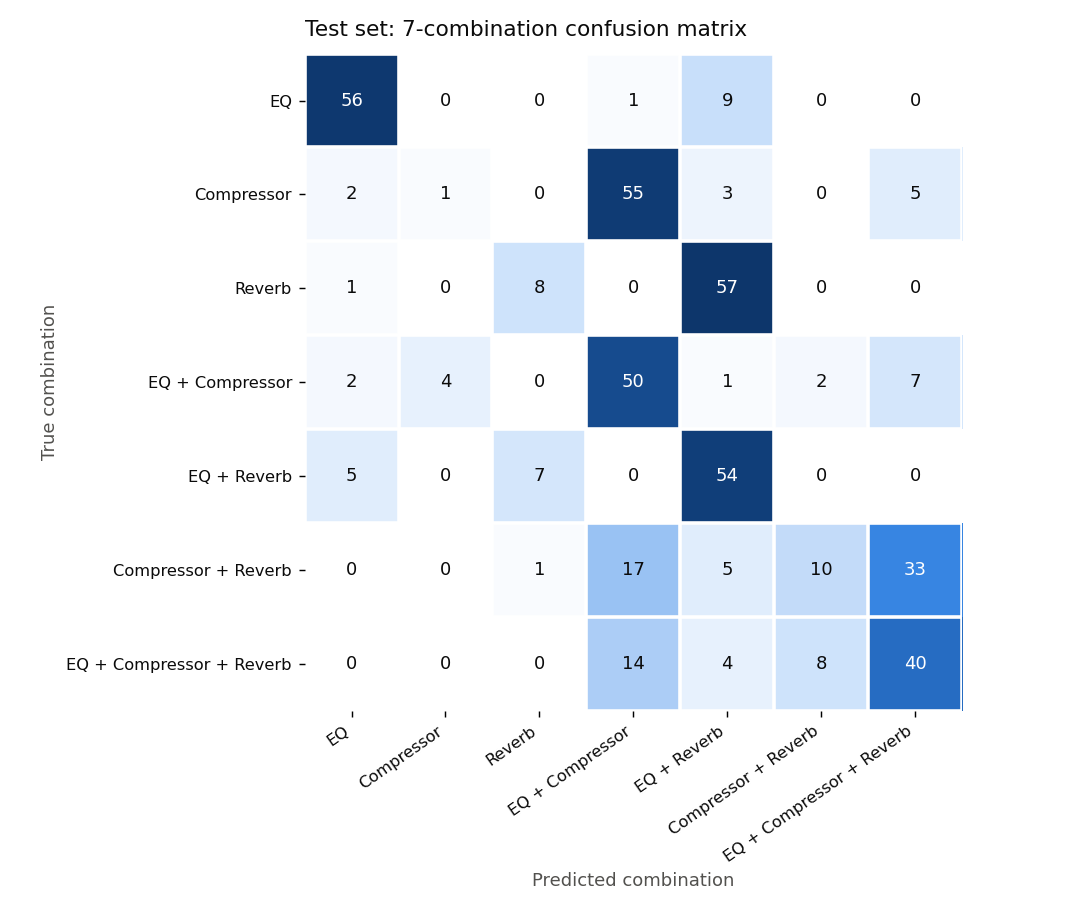

,EQ,Compressor,Reverb,EQ + Compressor,EQ + Reverb,Compressor + Reverb,EQ + Compressor + Reverb
true: EQ,56,0,0,1,9,0,0
true: Compressor,2,1,0,55,3,0,5
true: Reverb,1,0,8,0,57,0,0
true: EQ + Compressor,2,4,0,50,1,2,7
true: EQ + Reverb,5,0,7,0,54,0,0
true: Compressor + Reverb,0,0,1,17,5,10,33
true: EQ + Compressor + Reverb,0,0,0,14,4,8,40


In [46]:
cm_path = plot_confusion_matrix(TEST_METRICS["confusion_matrix"], os.path.join(CFG["RESULTS_DIR"], "plots", "test_confusion_matrix.png"))
display(Image(cm_path))
display(pd.DataFrame(TEST_METRICS["confusion_matrix"], index=[f"true: {n}" for n in COMBINATION_NAMES], columns=COMBINATION_NAMES))

## 26. Training Curves
Plots are regenerated from the history and saved to `results/plots/`. The last cell reads the TensorBoard event files directly — a fallback if the inline TensorBoard frame does not render on Kaggle.

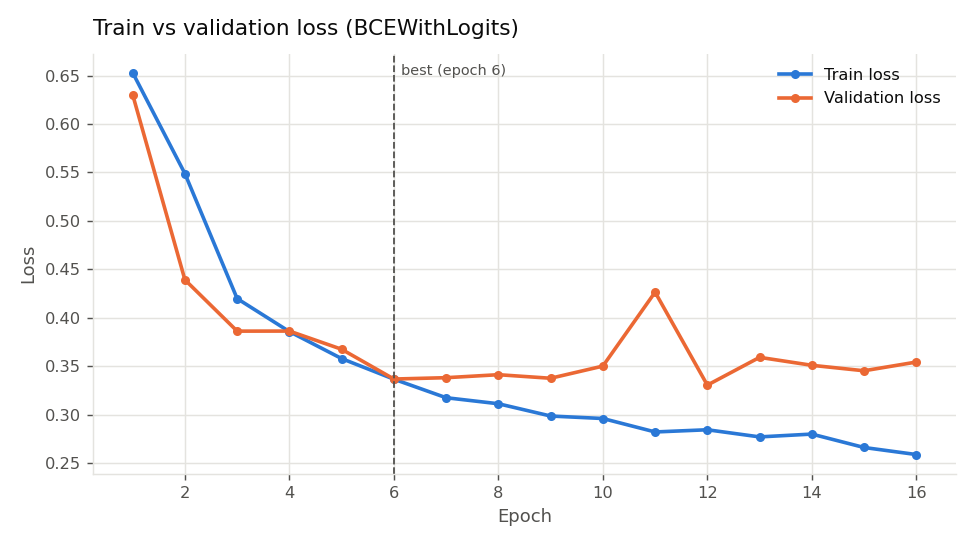

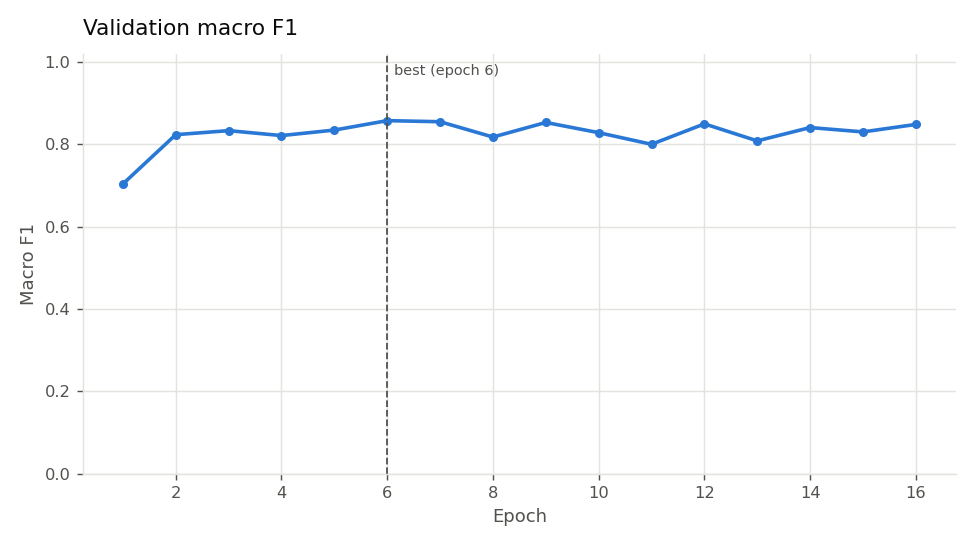

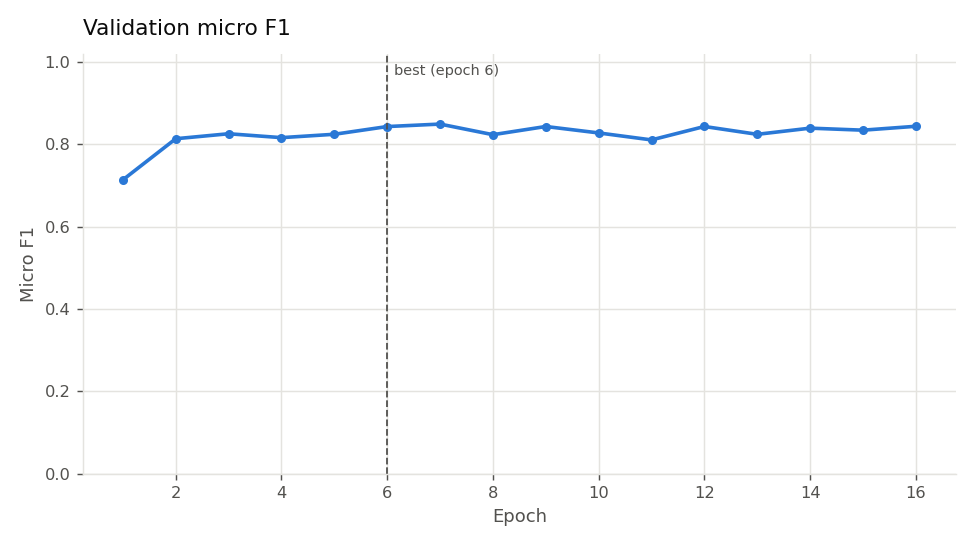

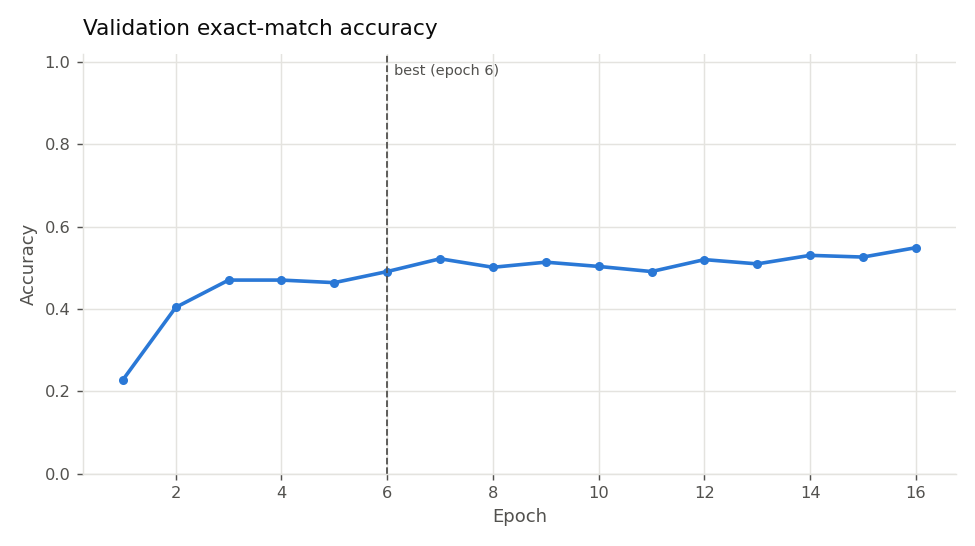

In [47]:
for p in plot_training_curves(HISTORY, os.path.join(CFG["RESULTS_DIR"], "plots")):
    display(Image(p))

In [48]:
try:
    from tensorboard.backend.event_processing.event_accumulator import EventAccumulator
    acc = EventAccumulator(CFG["TENSORBOARD_DIR"], size_guidance={"scalars": 0}); acc.Reload()
    tags = acc.Tags()["scalars"]
    print("TensorBoard scalar tags:", tags)
    tb = {t: pd.Series({e.step: e.value for e in acc.Scalars(t)}) for t in tags if not t.startswith(("train/loss_step", "learning_rate", "global_step", "epoch"))}
    display(pd.DataFrame(tb).tail(10).style.format(precision=4))
except Exception as e:
    print("Could not read TensorBoard events:", e)

TensorBoard scalar tags: ['train/loss_step', 'learning_rate', 'global_step', 'train/loss', 'validation/loss', 'validation/macro_f1', 'validation/micro_f1', 'validation/exact_match_accuracy', 'validation/combination_accuracy', 'EQ/precision', 'EQ/recall', 'EQ/f1', 'Compressor/precision', 'Compressor/recall', 'Compressor/f1', 'Reverb/precision', 'Reverb/recall', 'Reverb/f1', 'learning_rate_epoch', 'epoch', 'global_step_per_epoch']


,train/loss,validation/loss,validation/macro_f1,validation/micro_f1,validation/exact_match_accuracy,validation/combination_accuracy,EQ/precision,EQ/recall,EQ/f1,Compressor/precision,Compressor/recall,Compressor/f1,Reverb/precision,Reverb/recall,Reverb/f1
7,0.3175,0.3382,0.8545,0.8488,0.5217,0.5217,0.6261,0.8007,0.7027,0.9675,0.9710,0.9693,0.8376,0.9529,0.8915
8,0.3113,0.3413,0.8172,0.8230,0.5010,0.5010,0.6637,0.5362,0.5932,0.9882,0.9094,0.9472,0.9097,0.9130,0.9114
9,0.2986,0.3376,0.8527,0.8429,0.5135,0.5135,0.5969,0.8478,0.7006,0.9667,0.9457,0.9560,0.8767,0.9275,0.9014
10,0.2960,0.3501,0.8279,0.8272,0.5031,0.5031,0.6394,0.6232,0.6312,0.9778,0.9565,0.9670,0.9355,0.8406,0.8855
11,0.2821,0.4265,0.7997,0.8103,0.4907,0.4907,0.7432,0.4928,0.5926,0.9881,0.9022,0.9432,0.8467,0.8804,0.8632
12,0.2844,0.3305,0.8493,0.8429,0.5197,0.5197,0.6119,0.7428,0.6710,1.0000,0.9457,0.9721,0.8671,0.9457,0.9047
13,0.2770,0.3592,0.8080,0.8239,0.5093,0.5093,0.7345,0.4710,0.5740,0.9740,0.9493,0.9615,0.8323,0.9529,0.8885
14,0.2799,0.3510,0.8403,0.8389,0.5300,0.5300,0.6619,0.6739,0.6679,1.0000,0.9094,0.9526,0.8687,0.9348,0.9005
15,0.2661,0.3453,0.8298,0.8340,0.5259,0.5259,0.6883,0.5761,0.6272,0.9885,0.9312,0.9590,0.9114,0.8949,0.9031
16,0.2588,0.3543,0.8479,0.8434,0.5487,0.5487,0.6556,0.7174,0.6851,0.9888,0.9565,0.9724,0.9867,0.8043,0.8862


## 27. Final Results

In [49]:
FINAL = {
    "experiment": "Phase 1 — Log-Mel + Transformer — effect-type prediction (EQ, Compressor, Reverb)",
    "best_epoch": BEST_STATE["best_epoch"], "epochs_completed": int(hist_df.epoch.max()),
    "selection_metric": f"validation {BEST_STATE['best_metric_name']}",
    "validation_at_best": {k: float(best_row[k]) for k in ("validation_loss", "validation_macro_f1", "validation_micro_f1",
                                                          "validation_accuracy", "validation_combination_accuracy")},
    "test": {k: TEST_METRICS[k] for k in ("loss", "exact_match_accuracy", "combination_accuracy", "macro_f1", "micro_f1")}
            | {f"{e}/{m}": TEST_METRICS[f"{e}/{m}"] for e in EFFECTS for m in ("precision", "recall", "f1")},
    "trainable_parameters": N_PARAMS, "world_size": LATEST_STATE.get("world_size"),
    "dataset": CFG["HF_DATASET_ID"], "model_repo": CFG["HF_MODEL_ID"],
}
atomic_write_json(os.path.join(CFG["RESULTS_DIR"], "final_results.json"), FINAL)
comp = pd.DataFrame({
    "validation (best epoch)": [best_row["validation_loss"], best_row["validation_accuracy"], best_row["validation_combination_accuracy"], best_row["validation_macro_f1"], best_row["validation_micro_f1"]],
    "test": [TEST_METRICS["loss"], TEST_METRICS["exact_match_accuracy"], TEST_METRICS["combination_accuracy"], TEST_METRICS["macro_f1"], TEST_METRICS["micro_f1"]],
}, index=["loss", "exact-match accuracy", "7-combination accuracy", "macro F1", "micro F1"])
display(comp.style.format(precision=4))

,validation (best epoch),test
loss,0.3368,0.3705
exact-match accuracy,0.4907,0.4740
7-combination accuracy,0.4907,0.4740
macro F1,0.8571,0.8496
micro F1,0.8428,0.8355


## 28. Save / Push Final Model
`final/` = inference bundle (weights + config + label map + test metrics). One commit also pushes the model card (`README.md`), `results/` (history, plots, test metrics/predictions), TensorBoard `runs/`, the `fxp1/` source and `train.py`.

In [50]:
FINAL_DIR = os.path.join(WORK_DIR, "final")
shutil.rmtree(FINAL_DIR, ignore_errors=True); os.makedirs(FINAL_DIR)
torch.save(best_model.state_dict(), os.path.join(FINAL_DIR, "model.pt"))
shutil.copy2(os.path.join(BEST_DIR, "config.json"), os.path.join(FINAL_DIR, "config.json"))
shutil.copy2(os.path.join(BEST_DIR, "training_state.json"), os.path.join(FINAL_DIR, "training_state.json"))
atomic_write_json(os.path.join(FINAL_DIR, "label_map.json"), BEST_CONFIG["label_mapping"])
atomic_write_json(os.path.join(FINAL_DIR, "test_metrics.json"), TEST_METRICS)

card = build_model_card(eval_cfg, HISTORY, BEST_STATE, TEST_METRICS, SHAPES, N_PARAMS)
README_PATH = os.path.join(WORK_DIR, "README.md")
open(README_PATH, "w").write(card)

if hub.enabled:
    ok = hub.push(CFG["CHECKPOINT_DIR"], [], include_best=True, include_pointer=False,
                  extra_dirs={"final": FINAL_DIR, "results": CFG["RESULTS_DIR"], "fxp1": PKG_DIR,
                              os.path.relpath(CFG["TENSORBOARD_DIR"], WORK_DIR): CFG["TENSORBOARD_DIR"]},
                  extra_files={"README.md": README_PATH, "train.py": os.path.join(WORK_DIR, "train.py"),
                               "experiment_config.json": CONFIG_PATH},
                  commit_message=f"final model (best epoch {BEST_STATE['best_epoch']}) + test results")
    print("Pushed final model:", ok, f"-> https://huggingface.co/{CFG['HF_MODEL_ID']}")
else:
    print("Hub disabled — final model saved locally in", FINAL_DIR)

[18:14:51] HF push OK -> APINAJA/inverse-fx-phase1-logmel-transformer-v2 (40 files, 1.1s): - + best
Pushed final model: True -> https://huggingface.co/APINAJA/inverse-fx-phase1-logmel-transformer-v2


## 29. Final Experiment Summary

In [51]:
t = TEST_METRICS
print(f"""
================ PHASE 1 · LOG-MEL + TRANSFORMER · EFFECT-TYPE PREDICTION ================
Data        : {CFG['HF_DATASET_ID']}  (train {len(train_ds)} / val {len(val_ds)} / test {len(test_ds)})
Inputs      : dry_audio + wet_audio only, {CFG['SAMPLE_RATE']} Hz mono, {CFG['AUDIO_LENGTH_SECONDS']} s, float32
Features    : Log-Mel n_fft={CFG['N_FFT']} hop={CFG['HOP_LENGTH']} n_mels={CFG['N_MELS']} {CFG['F_MIN']:.0f}-{CFG['F_MAX']:.0f} Hz -> {SHAPES['dry_log_mel']} each
Fusion      : concat -> {SHAPES['fused']} -> Linear -> {SHAPES['projected']}
Transformer : {CFG['NUM_LAYERS']} layers, d_model {CFG['D_MODEL']}, {CFG['N_HEAD']} heads, FF {CFG['DIM_FEEDFORWARD']}, [CLS] pooling | {N_PARAMS:,} params
Output      : {SHAPES['logits']} logits [EQ, Compressor, Reverb], BCEWithLogitsLoss, threshold {CFG['THRESHOLD']}
Training    : {int(hist_df.epoch.max())} epochs on {LATEST_STATE.get('world_size')} process(es), AMP {CFG['USE_AMP']}, best epoch {BEST_STATE['best_epoch']}
Validation  : macro F1 {best_row['validation_macro_f1']:.4f} | 7-comb acc {best_row['validation_combination_accuracy']:.4f}  (best epoch)
TEST        : loss {t['loss']:.4f} | exact-match {t['exact_match_accuracy']:.4f} | 7-comb {t['combination_accuracy']:.4f} | macro F1 {t['macro_f1']:.4f} | micro F1 {t['micro_f1']:.4f}
Per effect  : """ + " | ".join(f"{e} P {t[e + '/precision']:.3f} R {t[e + '/recall']:.3f} F1 {t[e + '/f1']:.3f}" for e in EFFECTS) + f"""
Artifacts   : {CFG['RESULTS_DIR']} | {CFG['CHECKPOINT_DIR']} | {CFG['TENSORBOARD_DIR']}
Hub         : https://huggingface.co/{CFG['HF_MODEL_ID']}
==========================================================================================
Note: the test split has {len(test_ds)} pairs (~{len(test_ds) // 7} per combination, {len(test_ds) // 7} unseen dry clips from songs not used in training).
""")


================ PHASE 1 · LOG-MEL + TRANSFORMER · EFFECT-TYPE PREDICTION ================
Data        : APINAJA/inverse-fx-phase1-effect-type  (train 2191 / val 483 / test 462)
Inputs      : dry_audio + wet_audio only, 44100 Hz mono, 10.0 s, float32
Features    : Log-Mel n_fft=2048 hop=512 n_mels=128 20-20000 Hz -> (16, 128, 862) each
Fusion      : concat -> (16, 862, 256) -> Linear -> (16, 862, 256)
Transformer : 4 layers, d_model 256, 4 heads, FF 512, [CLS] pooling | 2,208,771 params
Output      : (16, 3) logits [EQ, Compressor, Reverb], BCEWithLogitsLoss, threshold 0.5
Training    : 16 epochs on 2 process(es), AMP True, best epoch 6
Validation  : macro F1 0.8571 | 7-comb acc 0.4907  (best epoch)
TEST        : loss 0.3705 | exact-match 0.4740 | 7-comb 0.4740 | macro F1 0.8496 | micro F1 0.8355
Per effect  : EQ P 0.577 R 0.920 F1 0.709 | Compressor P 0.996 R 0.932 F1 0.963 | Reverb P 0.894 R 0.860 F1 0.876
Artifacts   : /kaggle/working/results | /kaggle/working/checkpoints | /kaggle